# D4 符号 X スタビライザの閾値シミュレーション — v7（メインのシミュレーションコード）

**実行環境: Google Colab の CPU ランタイムで実行できます（GPU は不要）。** 重い部分は numba で高速化しています。
正当化コードは別ノートブック `D4_v7_validation.ipynb`（こちらは GPU 推奨）です。

v7 の要点（v6 との違いの詳細は「実装と未解決事項_v7.md」）:
1. **指標の分離**: 失敗を「charge（X スタビライザ側。flux 側が成功したショットに条件付け）」「flux（Z スタビライザ側）」「combined（どちらか）」に分けて保存・作図し、交点も指標ごとに出します。既定の主指標は charge です（X スタビライザの閾値）。
2. **circuit-level の電荷デコーダの重みを実回路に合わせた**: 実際の（ネイティブ CCZ）回路の故障表から、X チェック結果の反転率（約 6.4p）とデータの Z 型誤り率を一次の近似で求め、デコーダの事前分布に使います（`cl_decoder_prior="calibrated"`）。
3. **対照実験**: `dressing_treatment` で、同じプロトコル・同じ雑音のまま (a) dressing なし（3 枚の Z2 トーリック符号）、(b) dressing なし＋旧研究の $r=\kappa c p$ の Z 注入、を計算できます。非可換性の効果の切り分けと、旧研究の近似の評価に使います。
4. 実行条件の記録（manifest JSON）、旧研究のサロゲート（`engine="stim_surrogate"`）の seed 付き標本化。

物理を計算する中核（twisted-frame エンジン、JIT フラックス復号、終了処理）は v6 と同じです。

使い方: Cell 2 で `noise_model`（`depolarizing` / `phenomenological` / `circuit_level`）を選び、上から順に実行します。最初は `shots=2000` 程度で動作確認してください。

[Cell 1] Install（GPU 不要）

In [1]:
!pip -q install stim pymatching numpy pandas matplotlib numba

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.3/5.3 MB 25.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 625.9/625.9 kB 27.0 MB/s eta 0:00:00


[Cell 2] Setup & Config

各パラメータの意味と、正当化コードのパラメータとの対応は「実装と未解決事項_v7.md」にまとめました。
- `failure_metric="charge"`: X スタビライザ（電荷側）の閾値を求めるための主指標。`combined` は v6 の `logical_error_rate` と同じです。
- `dressing_treatment`: `"exact"` が D4 符号。`"none"`・`"kappa_injection"` は対照実験です（論文の比較図用）。
- `depolarizing` は符号容量型（測定誤りなし・雑音 1 ラウンド）です。旧研究の定義（測定誤りあり、R=L）は `depolarizing_meas_scale=1.0, depolarizing_rounds=None` で、phenomenological と同じ物理になります。
- `p_min=None, p_max=None` のときは、ノイズモデルごとの推奨範囲 `RECOMMENDED_P_RANGE` を使います。

In [2]:
from __future__ import annotations

import math
import os
import time
from dataclasses import dataclass
from typing import Dict, List, Optional, Sequence, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

try:
    import stim
except ImportError:
    stim = None

try:
    import tsim
except ImportError:
    tsim = None

try:
    import pymatching
except ImportError:
    pymatching = None

try:
    from scipy.stats import norm

    SCIPY_AVAILABLE = True
except ImportError:
    SCIPY_AVAILABLE = False

CFG = dict(
    # ===== 計算の方式 =====
    engine="twisted_frame",        # "twisted_frame"（dressed X チェックを厳密に扱う。非可換性込み）/ "stim_surrogate"（旧研究のサロゲート: bare MPP + r=κcp）
    dressing_treatment="exact",    # v7: "exact"（D4 符号）/ "none"（dressing なし = 3 枚の Z2 トーリック符号）/ "kappa_injection"（dressing なし + 旧研究の r=κcp 注入）
    failure_metric="charge",       # v7: 図・交点推定の主指標。"charge"（X スタビライザ側。flux 成功ショットに条件付け）/ "combined" / "flux"
    seed=20260927,                 # 乱数の基準 seed（各点の seed はこれと (L, p) から決定論的に作る）
    batch_size=20000,              # twisted_frame エンジンの 1 バッチのショット数（メモリ節約用）
    save_manifest=True,            # v7: 実行条件（CFG 全体・版・日時・環境）を JSON に保存
    # ===== プロトコルと復号器 =====
    logical_colors="rgb",    # 論理状態: x 方向ホロノミーのセクターを重ね合わせる色（"rgb" で 3 論理量、"r" で 1 論理量）
    x_check_order="rgb",     # 1 ラウンド内の dressed X チェックの測定順（色レイヤ）。非可換性はこの順序に依存する
    jit_boundary_offset=1.0, # JIT フラックス復号: 未解決事象が「未来境界」と組むコスト = w_t*(t - t_e + offset)
    # 電荷デコーダ事前分布に入れる r=κcp の κ（ノイズモデルごと。物理の標本化には入らない）。
    # 値は試行計算で最大の L の LER が最小になるものを選んだ（正当化コード (D) で再調整できる）
    tf_decoder_kappa={"depolarizing": 0.5, "phenomenological": 0.0, "circuit_level": 0.0},
    cl_decoder_prior="calibrated",  # v7: CL の電荷デコーダ事前分布。"calibrated"（実回路の故障表から較正）/ "legacy"（v6 と同じ旧 CL サロゲート）
    decoder_meas_floor_scale=0.5,   # 電荷デコーダ事前分布の測定反転確率の下限（×p, depolarizing/phenomenological）。測定誤り 0 でも時間方向の辺を確保
    depolarizing_rounds=1,   # depolarizing（符号容量型）の雑音ラウンド数（None なら rounds/L = 旧研究の定義）
    # ===== 旧研究のコードから引き継いだキー =====
    noise_model="phenomenological", #depolarizing, phenomenological, circuit_level
    L_values=[3, 5, 7, 9],      # 本番では 9 の追加を推奨（実装と未解決事項_v7.md）
    rounds=None,             # None -> L（depolarizing は depolarizing_rounds が優先）
    shots=10000,            # 研究用。動作確認は 2000 程度で
    p_min=None,              # None ならノイズモデルごとの推奨範囲 RECOMMENDED_P_RANGE を使う
    p_max=None,
    p_n=10,
    confidence_level=0.95,
    out_csv=None,            # None なら "d4_v7_X_memory_<model>_<engine>.csv"
    out_png=None,            # None なら "d4_v7_X_memory_<model>_<engine>.png"
    save_pdf=True,
    print_geometry_summary=True,
    run_self_checks=True,    # twisted_frame では幾何（平坦部分空間での可換性）と p=0 の無失敗を確認
    self_check_shots=300,
    depolarizing_data_scale=1.0,
    depolarizing_meas_scale=0.0,     # 符号容量型（測定は完全）。旧研究の定義（= phenomenological と同じ物理）は 1.0 かつ depolarizing_rounds=None
    depolarizing_dressing_scale=0.5, # 旧研究のサロゲートの κ_depol（stim_surrogate と kappa_injection で使用）
    depolarizing_dressing_mode="pairwise_graphlike",
    phenomenological_data_scale=1.0,
    phenomenological_meas_scale=1.0,
    phenomenological_kickback_scale=0.25,  # 旧研究のサロゲートの κ_pheno
    circuit_init_scale=0.60,
    circuit_1q_scale=0.35,
    circuit_2q_scale=1.00,
    circuit_noncliff_scale=1.00,     # twisted_frame: ネイティブ CCZ ゲート直後に 3 量子ビットそれぞれ DEPOLARIZE1(この値×p)
    circuit_idle_scale=0.40,
    circuit_meas_scale=1.00,
    circuit_kickback_scale=0.6,      # 旧研究のサロゲートの κ_circ
)

# ノイズモデルごとの推奨 p 範囲（v7 の試行計算で charge 指標の交点を含むことを確認した範囲。研究本番では交点付近を細かく）
RECOMMENDED_P_RANGE = {
    "depolarizing": (5e-2, 1.4e-1),
    "phenomenological": (1.2e-2, 3.0e-2),
    "circuit_level": (1.0e-3, 3.0e-3),
}

[Cell 3] Geometry & Stabilizers

緑 (g) チェックの CZ ペアの向きは、cup 積の定義どおり（$\int \tilde e''\cup\tilde v\cup\tilde e'$：赤を $e_{01}$、青を $e_{12}$）です。`count_noncommuting_x_check_pairs` は平坦部分空間での可換性を検査します。

In [3]:
Vertex = Tuple[int, int]
Edge = Tuple[Vertex, Vertex]
Triangle = Tuple[Vertex, Vertex, Vertex]
Color = str

COLORS: Tuple[Color, ...] = ("r", "g", "b")


def _vkey(v: Vertex) -> Tuple[int, int]:
    return v[0], v[1]


def _canon_edge(a: Vertex, b: Vertex) -> Edge:
    return (a, b) if _vkey(a) < _vkey(b) else (b, a)


def _ordered_pair(a: int, b: int) -> Tuple[int, int]:
    return (a, b) if a < b else (b, a)


def _clip_prob(p: float, upper: float = 0.499999) -> float:
    return min(upper, max(0.0, float(p)))


@dataclass(frozen=True)
class TriangulatedTorus:
    L: int
    vertices: List[Vertex]
    edges: List[Edge]
    triangles: List[Triangle]
    edge_index_of: Dict[Edge, int]
    vertex_to_edges: Dict[Vertex, Tuple[int, ...]]
    edge_to_triangles: Dict[int, Tuple[int, ...]]
    triangle_to_edges: List[Tuple[int, int, int]]

    @staticmethod
    def build(L: int) -> "TriangulatedTorus":
        verts: List[Vertex] = [(x, y) for y in range(L) for x in range(L)]
        tris: List[Triangle] = []
        for y in range(L):
            for x in range(L):
                v00 = (x, y)
                v10 = ((x + 1) % L, y)
                v01 = (x, (y + 1) % L)
                v11 = ((x + 1) % L, (y + 1) % L)
                tris.append((v00, v10, v11))
                tris.append((v00, v01, v11))

        edge_index_of: Dict[Edge, int] = {}
        triangle_to_edges: List[Tuple[int, int, int]] = []

        def get_edge_index(a: Vertex, b: Vertex) -> int:
            edge = _canon_edge(a, b)
            if edge not in edge_index_of:
                edge_index_of[edge] = len(edge_index_of)
            return edge_index_of[edge]

        for a, b, c in tris:
            eab = get_edge_index(a, b)
            ebc = get_edge_index(b, c)
            eca = get_edge_index(c, a)
            triangle_to_edges.append((eab, ebc, eca))

        edges = [None] * len(edge_index_of)
        for edge, index in edge_index_of.items():
            edges[index] = edge

        vertex_to_edges_lists: Dict[Vertex, List[int]] = {v: [] for v in verts}
        for edge_index, (a, b) in enumerate(edges):
            vertex_to_edges_lists[a].append(edge_index)
            vertex_to_edges_lists[b].append(edge_index)

        edge_to_triangles_lists: Dict[int, List[int]] = {
            edge_index: [] for edge_index in range(len(edges))
        }
        for triangle_index, (e0, e1, e2) in enumerate(triangle_to_edges):
            edge_to_triangles_lists[e0].append(triangle_index)
            edge_to_triangles_lists[e1].append(triangle_index)
            edge_to_triangles_lists[e2].append(triangle_index)

        return TriangulatedTorus(
            L=L,
            vertices=verts,
            edges=edges,
            triangles=tris,
            edge_index_of=edge_index_of,
            vertex_to_edges={
                v: tuple(sorted(edge_indices))
                for v, edge_indices in vertex_to_edges_lists.items()
            },
            edge_to_triangles={
                edge_index: tuple(sorted(triangles))
                for edge_index, triangles in edge_to_triangles_lists.items()
            },
            triangle_to_edges=triangle_to_edges,
        )


@dataclass(frozen=True)
class FaceZStabilizer:
    color: Color
    face_index: int
    edge_indices: Tuple[int, int, int]


@dataclass(frozen=True)
class VertexXCliffordStabilizer:
    color: Color
    vertex: Vertex
    x_edges: Tuple[int, ...]
    cz_edge_pairs: Tuple[Tuple[int, int], ...]
    cz_colors: Tuple[Color, Color]


@dataclass(frozen=True)
class D4Stabilizers:
    lat: TriangulatedTorus
    face_Z: List[FaceZStabilizer]
    vertex_X: List[VertexXCliffordStabilizer]


@dataclass(frozen=True)
class DressingPairEvent:
    qubits: Tuple[int, int]
    multiplicity: int


def edge_color_to_qubit(edge_index: int, color: Color) -> int:
    color_offset = {"r": 0, "g": 1, "b": 2}[color]
    return 3 * edge_index + color_offset


def qubit_to_edge_color(q: int) -> Tuple[int, Color]:
    return q // 3, COLORS[q % 3]


def build_d4_stabilizers(lat: TriangulatedTorus) -> D4Stabilizers:
    face_Z: List[FaceZStabilizer] = []
    for face_index, edge_indices in enumerate(lat.triangle_to_edges):
        for color in COLORS:
            face_Z.append(
                FaceZStabilizer(
                    color=color,
                    face_index=face_index,
                    edge_indices=edge_indices,
                )
            )

    cz_pairs_by_color: Dict[Color, Dict[Vertex, List[Tuple[int, int]]]] = {
        color: {vertex: [] for vertex in lat.vertices}
        for color in COLORS
    }

    for v0, v1, v2 in lat.triangles:
        e01 = lat.edge_index_of[_canon_edge(v0, v1)]
        e12 = lat.edge_index_of[_canon_edge(v1, v2)]
        cz_pairs_by_color["r"][v0].append((e01, e12))
        # v6: cup-product order a_r(01) a_b(12) for green (Kobayashi-Zhu-Hsin SM); old code had (e01, e12)
        cz_pairs_by_color["g"][v1].append((e12, e01))
        cz_pairs_by_color["b"][v2].append((e01, e12))

    partner_colors = {
        "r": ("g", "b"),
        "g": ("b", "r"),
        "b": ("r", "g"),
    }

    vertex_X: List[VertexXCliffordStabilizer] = []
    for vertex in lat.vertices:
        incident_edges = lat.vertex_to_edges[vertex]
        for color in COLORS:
            vertex_X.append(
                VertexXCliffordStabilizer(
                    color=color,
                    vertex=vertex,
                    x_edges=incident_edges,
                    cz_edge_pairs=tuple(cz_pairs_by_color[color][vertex]),
                    cz_colors=partner_colors[color],
                )
            )

    return D4Stabilizers(lat=lat, face_Z=face_Z, vertex_X=vertex_X)


def build_dual_x_observable_paths(lat: TriangulatedTorus) -> List[List[int]]:
    def edge_between(a: Vertex, b: Vertex) -> int:
        return lat.edge_index_of[_canon_edge(a, b)]

    obs_paths: List[List[int]] = []
    for color in COLORS:
        path_x_dual: List[int] = []
        for y in range(lat.L):
            e1 = edge_between((0, y), (1, y))
            e2 = edge_between((0, y), (1, (y + 1) % lat.L))
            path_x_dual.extend([edge_color_to_qubit(e1, color), edge_color_to_qubit(e2, color)])
        obs_paths.append(path_x_dual)

        path_y_dual: List[int] = []
        for x in range(lat.L):
            e1 = edge_between((x, 0), (x, 1))
            e2 = edge_between((x, 0), ((x + 1) % lat.L, 1))
            path_y_dual.extend([edge_color_to_qubit(e1, color), edge_color_to_qubit(e2, color)])
        obs_paths.append(path_y_dual)

    return obs_paths


def build_vertex_x_measurement_supports(stab: D4Stabilizers) -> List[List[int]]:
    x_stabs_qubits: List[List[int]] = []
    for v_stab in stab.vertex_X:
        x_stabs_qubits.append(
            [edge_color_to_qubit(edge_index, v_stab.color) for edge_index in v_stab.x_edges]
        )
    return x_stabs_qubits


def build_pairwise_dressing_events(stab: D4Stabilizers) -> List[DressingPairEvent]:
    counts: Dict[Tuple[int, int], int] = {}
    for v_stab in stab.vertex_X:
        color1, color2 = v_stab.cz_colors
        for edge1, edge2 in v_stab.cz_edge_pairs:
            q1 = edge_color_to_qubit(edge1, color1)
            q2 = edge_color_to_qubit(edge2, color2)
            counts[_ordered_pair(q1, q2)] = counts.get(_ordered_pair(q1, q2), 0) + 1
    return [
        DressingPairEvent(qubits=pair, multiplicity=counts[pair])
        for pair in sorted(counts)
    ]


def build_dressing_qubit_incidence(
    pair_events: Sequence[DressingPairEvent],
) -> Dict[int, int]:
    incidence: Dict[int, int] = {}
    for event in pair_events:
        q1, q2 = event.qubits
        incidence[q1] = incidence.get(q1, 0) + event.multiplicity
        incidence[q2] = incidence.get(q2, 0) + event.multiplicity
    return incidence


def summarize_geometry(stab: D4Stabilizers) -> Dict[str, float]:
    pair_events = build_pairwise_dressing_events(stab)
    incidence = build_dressing_qubit_incidence(pair_events)
    red_counts = [len(v_stab.cz_edge_pairs) for v_stab in stab.vertex_X if v_stab.color == "r"]
    return {
        "vertices": float(len(stab.lat.vertices)),
        "edges": float(len(stab.lat.edges)),
        "triangles": float(len(stab.lat.triangles)),
        "x_checks": float(len(stab.vertex_X)),
        "face_z_checks": float(len(stab.face_Z)),
        "unique_dressing_pairs": float(len(pair_events)),
        "max_dressing_incidence": float(max(incidence.values(), default=0)),
        "avg_red_pairs_per_vertex": float(sum(red_counts) / len(red_counts)),
    }

def _gf2_rank(rows: np.ndarray) -> int:
    M = (np.array(rows, dtype=np.uint8) & 1).copy()
    r = 0
    for c in range(M.shape[1]):
        piv = next((i for i in range(r, M.shape[0]) if M[i, c]), None)
        if piv is None:
            continue
        M[[r, piv]] = M[[piv, r]]
        for i in range(M.shape[0]):
            if i != r and M[i, c]:
                M[i] ^= M[r]
        r += 1
        if r == M.shape[0]:
            break
    return r


def count_noncommuting_x_check_pairs(stab: D4Stabilizers) -> Tuple[int, int]:
    """v6: dressed X チェック対の交換子を検査する。
    戻り値 = (演算子として非可換な対の数, 平坦（Z チェックが全て +1）な部分空間でも非可換な対の数)。
    正しい D4 符号では後者は 0（Kobayashi-Zhu-Hsin SM）。旧版の緑の向きでは L=3 で 90 対が非可換だった。"""
    n = 3 * len(stab.lat.edges)
    data = []
    for vs in stab.vertex_X:
        sv = np.zeros(n, np.uint8)
        for e in vs.x_edges:
            sv[edge_color_to_qubit(e, vs.color)] ^= 1
        prs = [(edge_color_to_qubit(a, vs.cz_colors[0]), edge_color_to_qubit(b, vs.cz_colors[1])) for a, b in vs.cz_edge_pairs]
        data.append((sv, prs))
    F = np.zeros((len(stab.face_Z), n), np.uint8)
    for i, fz in enumerate(stab.face_Z):
        for e in fz.edge_indices:
            F[i, edge_color_to_qubit(e, fz.color)] ^= 1
    rF = _gf2_rank(F)
    op_nc = flat_nc = 0
    for A in range(len(data)):
        for B in range(A + 1, len(data)):
            (sA, pA), (sB, pB) = data[A], data[B]
            y = np.zeros(n, np.uint8)
            c = 0
            for (i, j), sv in [(pr, sB) for pr in pA] + [(pr, sA) for pr in pB]:
                y[i] ^= sv[j]
                y[j] ^= sv[i]
                c ^= int(sv[i]) & int(sv[j])
            if y.any() or c:
                op_nc += 1
                if c or _gf2_rank(np.vstack([F, y])) > rF:
                    flat_nc += 1
    return op_nc, flat_nc

[Cell 4] Depolarizing Engine（旧研究のサロゲート回路）

旧研究の Stim 回路（bare MPP + $r=\kappa c p$ 注入）。v7 では (a) 電荷デコーダの事前分布（最終読み出しを無雑音にした DEM）と、(b) `engine="stim_surrogate"` での旧手法の再現に使います。

In [4]:
@dataclass(frozen=True)
class DemXArtifacts:
    circuit: "stim.Circuit"
    dem: "stim.DetectorErrorModel"
    n_observables: int
    model_label: str


PhenomenologicalXArtifacts = DemXArtifacts
CircuitLevelXArtifacts = DemXArtifacts
DepolarizingXArtifacts = DemXArtifacts


def _append_mpp_round(
    circuit: "stim.Circuit",
    x_stabs_qubits: Sequence[Sequence[int]],
    meas_p: float,
) -> None:
    targets: List["stim.GateTarget"] = []
    for qubits in x_stabs_qubits:
        for index, q in enumerate(qubits):
            targets.append(stim.target_x(q))
            if index < len(qubits) - 1:
                targets.append(stim.target_combiner())
    if meas_p > 0:
        circuit.append("MPP", targets, meas_p)
    else:
        circuit.append("MPP", targets)


def _pair_channel_probs(mode: str, r: float) -> Optional[List[float]]:
    r = _clip_prob(r)
    if r <= 0:
        return None

    probs = [0.0] * 15
    if mode == "pairwise_graphlike":
        probs[2] = r * (1.0 - r)
        probs[11] = r * (1.0 - r)
        probs[14] = r * r
        return probs
    if mode == "pessimistic_pairwise":
        probs[14] = min(0.499999, 1.5 * r)
        return probs
    raise ValueError(f"Unknown dressing mode: {mode}")


def _resolve_depolarizing_params(
    *,
    p: float,
    dressing_mode: Optional[str],
    data_scale: Optional[float],
    meas_scale: Optional[float],
    dressing_scale: Optional[float],
) -> Dict[str, float | str]:
    mode = str(CFG["depolarizing_dressing_mode"] if dressing_mode is None else dressing_mode)
    data_p = _clip_prob(float(CFG["depolarizing_data_scale"] if data_scale is None else data_scale) * p)
    meas_p = _clip_prob(float(CFG["depolarizing_meas_scale"] if meas_scale is None else meas_scale) * p)
    dress_scale = max(
        0.0,
        float(CFG["depolarizing_dressing_scale"] if dressing_scale is None else dressing_scale),
    )
    return {
        "dressing_mode": mode,
        "data_p": data_p,
        "meas_p": meas_p,
        "dressing_scale": dress_scale,
    }


def build_depolarizing_x_circuit(
    *,
    stab: D4Stabilizers,
    rounds: int,
    p: float,
    data_scale: Optional[float] = None,
    meas_scale: Optional[float] = None,
    dressing_scale: Optional[float] = None,
    dressing_mode: Optional[str] = None,
    final_noise: bool = True,
) -> DepolarizingXArtifacts:
    if stim is None:
        raise RuntimeError("stim is not available.")

    params = _resolve_depolarizing_params(
        p=p,
        dressing_mode=dressing_mode,
        data_scale=data_scale,
        meas_scale=meas_scale,
        dressing_scale=dressing_scale,
    )

    lat = stab.lat
    n_data = 3 * len(lat.edges)
    data = list(range(n_data))
    obs_paths = build_dual_x_observable_paths(lat)
    n_obs = len(obs_paths)
    x_stabs_qubits = build_vertex_x_measurement_supports(stab)
    n_checks = len(x_stabs_qubits)
    pair_events = build_pairwise_dressing_events(stab)
    incidence = build_dressing_qubit_incidence(pair_events)
    circuit = stim.Circuit()
    circuit.append("R", data)
    circuit.append("H", data)

    data_p = float(params["data_p"])
    meas_p = float(params["meas_p"])
    mode = str(params["dressing_mode"])
    base_dressing_rate = float(params["dressing_scale"]) * (2.0 * data_p / 3.0)

    for round_index in range(rounds):
        if data_p > 0:
            circuit.append("DEPOLARIZE1", data, data_p)

        if mode != "off" and base_dressing_rate > 0:
            for event in pair_events:
                q1, q2 = event.qubits
                local_norm = max(incidence.get(q1, 1), incidence.get(q2, 1))
                pair_rate = base_dressing_rate * event.multiplicity / max(1, local_norm)
                probs = _pair_channel_probs(mode, pair_rate)
                if probs is not None:
                    circuit.append("PAULI_CHANNEL_2", [q1, q2], probs)

        _append_mpp_round(circuit, x_stabs_qubits, meas_p=meas_p)

        if round_index == 0:
            for check_index in range(n_checks):
                cur = stim.target_rec(-(n_checks - check_index))
                circuit.append("DETECTOR", [cur])
        else:
            for check_index in range(n_checks):
                cur = stim.target_rec(-(n_checks - check_index))
                prev = stim.target_rec(-(2 * n_checks - check_index))
                circuit.append("DETECTOR", [cur, prev])

    if final_noise and data_p > 0:  # v6: final_noise=False -> noiseless final readout (= perfect final round)
        circuit.append("DEPOLARIZE1", data, data_p)
    if final_noise and meas_p > 0:
        circuit.append("Z_ERROR", data, meas_p)

    circuit.append("H", data)
    circuit.append("M", data)

    for check_index, qubits in enumerate(x_stabs_qubits):
        last_mpp = stim.target_rec(-(n_data + n_checks - check_index))
        recs = [stim.target_rec(-(n_data - q)) for q in qubits]
        circuit.append("DETECTOR", [last_mpp] + recs)

    for observable_index, path in enumerate(obs_paths):
        targets = [stim.target_rec(-(n_data - q)) for q in path]
        circuit.append("OBSERVABLE_INCLUDE", targets, observable_index)

    dem = circuit.detector_error_model(
        decompose_errors=True,
        approximate_disjoint_errors=True,
    )
    return DepolarizingXArtifacts(
        circuit=circuit,
        dem=dem,
        n_observables=n_obs,
        model_label="depolarizing_surrogate_v2",
    )


def build_depolarizing_approx_baseline_circuit(
    *,
    stab: D4Stabilizers,
    rounds: int,
    p: float,
    data_scale: float = 1.0,
    meas_scale: float = 1.0,
    kickback_scale: float = 1.0,
) -> DepolarizingXArtifacts:
    if stim is None:
        raise RuntimeError("stim is not available.")

    lat = stab.lat
    n_data = 3 * len(lat.edges)
    data = list(range(n_data))
    obs_paths = build_dual_x_observable_paths(lat)
    x_stabs_qubits = build_vertex_x_measurement_supports(stab)
    pair_events = build_pairwise_dressing_events(stab)

    data_p = _clip_prob(data_scale * p)
    meas_p = _clip_prob(meas_scale * p)
    r_xy = _clip_prob(kickback_scale * (2.0 * data_p / 3.0))
    kick_probs = [0.0] * 15
    if r_xy > 0:
        kick_probs[2] = r_xy * (1.0 - r_xy)
        kick_probs[11] = r_xy * (1.0 - r_xy)
        kick_probs[14] = r_xy * r_xy

    circuit = stim.Circuit()
    circuit.append("R", data)
    circuit.append("H", data)

    n_checks = len(x_stabs_qubits)
    for round_index in range(rounds):
        if data_p > 0:
            circuit.append("DEPOLARIZE1", data, data_p)
        if r_xy > 0:
            for event in pair_events:
                circuit.append("PAULI_CHANNEL_2", list(event.qubits), kick_probs)
        _append_mpp_round(circuit, x_stabs_qubits, meas_p=meas_p)
        if round_index == 0:
            for check_index in range(n_checks):
                cur = stim.target_rec(-(n_checks - check_index))
                circuit.append("DETECTOR", [cur])
        else:
            for check_index in range(n_checks):
                cur = stim.target_rec(-(n_checks - check_index))
                prev = stim.target_rec(-(2 * n_checks - check_index))
                circuit.append("DETECTOR", [cur, prev])

    if data_p > 0:
        circuit.append("DEPOLARIZE1", data, data_p)
    if meas_p > 0:
        circuit.append("Z_ERROR", data, meas_p)
    circuit.append("H", data)
    circuit.append("M", data)

    for check_index, qubits in enumerate(x_stabs_qubits):
        last_mpp = stim.target_rec(-(n_data + n_checks - check_index))
        recs = [stim.target_rec(-(n_data - q)) for q in qubits]
        circuit.append("DETECTOR", [last_mpp] + recs)

    for observable_index, path in enumerate(obs_paths):
        targets = [stim.target_rec(-(n_data - q)) for q in path]
        circuit.append("OBSERVABLE_INCLUDE", targets, observable_index)

    dem = circuit.detector_error_model(
        decompose_errors=True,
        approximate_disjoint_errors=True,
    )
    return DepolarizingXArtifacts(
        circuit=circuit,
        dem=dem,
        n_observables=len(obs_paths),
        model_label="depolarizing_approx_baseline",
    )

[Cell 5] Phenomenological Engine（旧研究のサロゲート回路）

役割は Cell 4 と同じです。v7 の circuit-level の較正済み事前分布も、この回路（データ・測定の率を指定）で作ります。

In [5]:
@dataclass(frozen=True)
class NonCliffordInteractionSite:
    pair_qubits: Tuple[int, int]
    anchor_qubit: int


@dataclass(frozen=True)
class CircuitLevelCheckSchedule:
    check_index: int
    color: Color
    vertex: Vertex
    x_qubits: Tuple[int, ...]
    noncliff_sites: Tuple[NonCliffordInteractionSite, ...]


@dataclass(frozen=True)
class EffectiveFaultEvent:
    location_kind: str
    source_check: int
    probability: float
    pauli_targets: Tuple[Tuple[str, int], ...]
    touched_checks: Tuple[int, ...]
    touched_observables: Tuple[int, ...]
    graphlike: bool
    explanation: str


@dataclass(frozen=True)
class CircuitLevelSchedule:
    n_data: int
    obs_paths: List[List[int]]
    x_stabs_qubits: List[List[int]]
    check_schedules: Tuple[CircuitLevelCheckSchedule, ...]
    qubit_to_checks: Dict[int, Tuple[int, ...]]
    qubit_to_observables: Dict[int, Tuple[int, ...]]


@dataclass(frozen=True)
class CircuitLevelNoiseSummary:
    prep_depolarize_p: float
    round_depolarize_p: Dict[int, float]
    tail_depolarize_p: Dict[int, float]
    single_noncliff_channels: Dict[int, Tuple[float, float, float]]
    correlated_events: Tuple[EffectiveFaultEvent, ...]
    meas_flip_p: float
    final_readout_flip_p: float
    model_label: str


def _combine_independent_probabilities(*rates: float, upper: float = 0.499999) -> float:
    keep = 1.0
    for rate in rates:
        clipped = min(0.999999, max(0.0, float(rate)))
        keep *= 1.0 - clipped
    return min(upper, max(0.0, 1.0 - keep))


def _build_qubit_incidence_map(
    supports: Sequence[Sequence[int]],
) -> Dict[int, Tuple[int, ...]]:
    out: Dict[int, List[int]] = {}
    for index, qubits in enumerate(supports):
        for q in qubits:
            out.setdefault(q, []).append(index)
    return {q: tuple(indices) for q, indices in out.items()}


def build_circuit_level_schedule(stab: D4Stabilizers) -> CircuitLevelSchedule:
    lat = stab.lat
    x_stabs_qubits = build_vertex_x_measurement_supports(stab)
    obs_paths = build_dual_x_observable_paths(lat)
    qubit_to_checks = _build_qubit_incidence_map(x_stabs_qubits)
    qubit_to_observables = _build_qubit_incidence_map(obs_paths)

    check_schedules: List[CircuitLevelCheckSchedule] = []
    for check_index, v_stab in enumerate(stab.vertex_X):
        sites: List[NonCliffordInteractionSite] = []
        for edge1, edge2 in v_stab.cz_edge_pairs:
            sites.append(
                NonCliffordInteractionSite(
                    pair_qubits=(
                        edge_color_to_qubit(edge1, v_stab.cz_colors[0]),
                        edge_color_to_qubit(edge2, v_stab.cz_colors[1]),
                    ),
                    anchor_qubit=edge_color_to_qubit(edge1, v_stab.color),
                )
            )
        check_schedules.append(
            CircuitLevelCheckSchedule(
                check_index=check_index,
                color=v_stab.color,
                vertex=v_stab.vertex,
                x_qubits=tuple(x_stabs_qubits[check_index]),
                noncliff_sites=tuple(sites),
            )
        )

    return CircuitLevelSchedule(
        n_data=3 * len(lat.edges),
        obs_paths=obs_paths,
        x_stabs_qubits=x_stabs_qubits,
        check_schedules=tuple(check_schedules),
        qubit_to_checks=qubit_to_checks,
        qubit_to_observables=qubit_to_observables,
    )


def _resolve_circuit_level_params(p: float) -> Dict[str, float]:
    return {
        "init_p": _clip_prob(float(CFG["circuit_init_scale"]) * p),
        "oneq_p": _clip_prob(float(CFG["circuit_1q_scale"]) * p),
        "twoq_p": _clip_prob(float(CFG["circuit_2q_scale"]) * p),
        "noncliff_p": _clip_prob(float(CFG["circuit_noncliff_scale"]) * p),
        "idle_p": _clip_prob(float(CFG["circuit_idle_scale"]) * p),
        "meas_p": _clip_prob(float(CFG["circuit_meas_scale"]) * p),
    }


def _make_fault_event(
    *,
    schedule: CircuitLevelSchedule,
    source_check: int,
    location_kind: str,
    probability: float,
    pauli_targets: Sequence[Tuple[str, int]],
    explanation: str,
) -> EffectiveFaultEvent:
    touched_checks = set()
    touched_observables = set()
    for axis, qubit in pauli_targets:
        if axis in ("Y", "Z"):
            touched_checks.update(schedule.qubit_to_checks.get(qubit, ()))
            touched_observables.update(schedule.qubit_to_observables.get(qubit, ()))
    return EffectiveFaultEvent(
        location_kind=location_kind,
        source_check=source_check,
        probability=_clip_prob(probability),
        pauli_targets=tuple(pauli_targets),
        touched_checks=tuple(sorted(touched_checks)),
        touched_observables=tuple(sorted(touched_observables)),
        graphlike=(len(touched_checks) <= 2 and len(touched_observables) <= 1),
        explanation=explanation,
    )


def enumerate_local_fault_events(
    *,
    schedule: CircuitLevelSchedule,
    p: float,
) -> CircuitLevelNoiseSummary:
    params = _resolve_circuit_level_params(p)
    pair_incidence: Dict[int, int] = {}
    max_check_degree = max((len(v) for v in schedule.qubit_to_checks.values()), default=1)
    for check in schedule.check_schedules:
        for site in check.noncliff_sites:
            q1, q2 = site.pair_qubits
            pair_incidence[q1] = pair_incidence.get(q1, 0) + 1
            pair_incidence[q2] = pair_incidence.get(q2, 0) + 1
    max_pair_degree = max(pair_incidence.values(), default=1)

    prep_depolarize_p = _combine_independent_probabilities(
        params["init_p"],
        params["oneq_p"],
    )

    round_depolarize_p: Dict[int, float] = {}
    tail_depolarize_p: Dict[int, float] = {}
    single_noncliff_channels: Dict[int, Tuple[float, float, float]] = {}

    for q in range(schedule.n_data):
        check_degree = len(schedule.qubit_to_checks.get(q, ()))
        pair_degree = pair_incidence.get(q, 0)
        clifford_round_p = params["twoq_p"] * check_degree / max(1, max_check_degree)
        round_depol = _combine_independent_probabilities(
            params["idle_p"],
            0.5 * params["oneq_p"],
            0.5 * clifford_round_p,
        )
        tail_depol = _combine_independent_probabilities(
            params["idle_p"],
            0.25 * params["oneq_p"],
        )
        if round_depol > 0:
            round_depolarize_p[q] = round_depol
        if tail_depol > 0:
            tail_depolarize_p[q] = tail_depol

        if pair_degree > 0:
            propagated_single_p = _clip_prob(
                0.35 * params["noncliff_p"] * pair_degree / max(1, max_pair_degree)
            )
            if propagated_single_p > 0:
                single_noncliff_channels[q] = (
                    0.15 * propagated_single_p,
                    0.35 * propagated_single_p,
                    0.50 * propagated_single_p,
                )

    local_pair_p = _clip_prob(0.45 * params["noncliff_p"] / max(1, max_pair_degree))
    local_hook_p = _clip_prob(0.35 * params["noncliff_p"] / max(1, max_pair_degree))

    events: List[EffectiveFaultEvent] = []
    for check in schedule.check_schedules:
        for site in check.noncliff_sites:
            q1, q2 = site.pair_qubits
            anchor = site.anchor_qubit

            if local_pair_p > 0:
                events.append(
                    _make_fault_event(
                        schedule=schedule,
                        source_check=check.check_index,
                        location_kind="nonclifford_interaction",
                        probability=0.50 * local_pair_p,
                        pauli_targets=(("Z", q1), ("Z", q2)),
                        explanation=(
                            "Propagated kickback on the dressed pair, reduced to an end-of-round ZZ event."
                        ),
                    )
                )
                events.append(
                    _make_fault_event(
                        schedule=schedule,
                        source_check=check.check_index,
                        location_kind="nonclifford_interaction",
                        probability=0.25 * local_pair_p,
                        pauli_targets=(("Y", q1), ("Z", q2)),
                        explanation=(
                            "A non-Clifford local Pauli fault can leave one partner with residual Y while kicking Z to the other."
                        ),
                    )
                )
                events.append(
                    _make_fault_event(
                        schedule=schedule,
                        source_check=check.check_index,
                        location_kind="nonclifford_interaction",
                        probability=0.25 * local_pair_p,
                        pauli_targets=(("Z", q1), ("Y", q2)),
                        explanation=(
                            "Mirror image of the propagated YZ event on the dressed pair."
                        ),
                    )
                )

            if local_hook_p > 0:
                events.append(
                    _make_fault_event(
                        schedule=schedule,
                        source_check=check.check_index,
                        location_kind="nonclifford_interaction",
                        probability=0.50 * local_hook_p,
                        pauli_targets=(("Z", anchor), ("Z", q1)),
                        explanation=(
                            "Ancilla-control fault approximated as a graphlike hook from the measured color to one dressed partner."
                        ),
                    )
                )
                events.append(
                    _make_fault_event(
                        schedule=schedule,
                        source_check=check.check_index,
                        location_kind="nonclifford_interaction",
                        probability=0.50 * local_hook_p,
                        pauli_targets=(("Z", anchor), ("Z", q2)),
                        explanation=(
                            "Second half of the graphlike hook approximation from the measured color to the other dressed partner."
                        ),
                    )
                )

    meas_flip_p = _combine_independent_probabilities(
        params["meas_p"],
        0.50 * params["init_p"],
        0.50 * params["oneq_p"],
        0.25 * params["twoq_p"],
    )
    final_readout_flip_p = _combine_independent_probabilities(
        params["meas_p"],
        0.50 * params["idle_p"],
    )

    return CircuitLevelNoiseSummary(
        prep_depolarize_p=prep_depolarize_p,
        round_depolarize_p=round_depolarize_p,
        tail_depolarize_p=tail_depolarize_p,
        single_noncliff_channels=single_noncliff_channels,
        correlated_events=tuple(events),
        meas_flip_p=meas_flip_p,
        final_readout_flip_p=final_readout_flip_p,
        model_label="circuit_level_effective_v1_graphlike_hooks",
    )


def _append_correlated_pauli_event(
    circuit: "stim.Circuit",
    event: EffectiveFaultEvent,
) -> None:
    if event.probability <= 0:
        return
    targets: List["stim.GateTarget"] = []
    for axis, qubit in event.pauli_targets:
        if axis == "X":
            targets.append(stim.target_x(qubit))
        elif axis == "Y":
            targets.append(stim.target_y(qubit))
        elif axis == "Z":
            targets.append(stim.target_z(qubit))
        else:
            raise ValueError(f"Unsupported Pauli axis: {axis}")
    circuit.append("CORRELATED_ERROR", targets, event.probability)


def _append_detector_layout(
    circuit: "stim.Circuit",
    *,
    round_index: int,
    n_checks: int,
) -> None:
    if round_index == 0:
        for check_index in range(n_checks):
            cur = stim.target_rec(-(n_checks - check_index))
            circuit.append("DETECTOR", [cur])
        return

    for check_index in range(n_checks):
        cur = stim.target_rec(-(n_checks - check_index))
        prev = stim.target_rec(-(2 * n_checks - check_index))
        circuit.append("DETECTOR", [cur, prev])


def _append_final_readout_layout(
    circuit: "stim.Circuit",
    *,
    x_stabs_qubits: Sequence[Sequence[int]],
    obs_paths: Sequence[Sequence[int]],
    n_data: int,
) -> None:
    n_checks = len(x_stabs_qubits)
    for check_index, qubits in enumerate(x_stabs_qubits):
        last_mpp = stim.target_rec(-(n_data + n_checks - check_index))
        recs = [stim.target_rec(-(n_data - q)) for q in qubits]
        circuit.append("DETECTOR", [last_mpp] + recs)

    for observable_index, path in enumerate(obs_paths):
        targets = [stim.target_rec(-(n_data - q)) for q in path]
        circuit.append("OBSERVABLE_INCLUDE", targets, observable_index)


def _phenomenological_kickback_probs(kick_p: float) -> Optional[List[float]]:
    kick_p = _clip_prob(kick_p)
    if kick_p <= 0:
        return None

    # A hidden ancilla-phase fault can dress either member of the CZ pair with Z,
    # or both members simultaneously, without introducing X/Y components.
    probs = [0.0] * 15
    probs[2] = kick_p * (1.0 - kick_p)   # IZ
    probs[11] = kick_p * (1.0 - kick_p)  # ZI
    probs[14] = kick_p * kick_p          # ZZ
    return probs


def _resolve_phenomenological_params(
    *,
    p: float,
    data_scale: Optional[float],
    meas_scale: Optional[float],
    kickback_scale: Optional[float],
) -> Dict[str, float]:
    data_p = _clip_prob(float(CFG["phenomenological_data_scale"] if data_scale is None else data_scale) * p)
    meas_p = _clip_prob(float(CFG["phenomenological_meas_scale"] if meas_scale is None else meas_scale) * p)
    kick_p = _clip_prob(float(CFG["phenomenological_kickback_scale"] if kickback_scale is None else kickback_scale) * p)
    return {"data_p": data_p, "meas_p": meas_p, "kick_p": kick_p}


def _append_phenomenological_kickback(
    circuit: "stim.Circuit",
    *,
    stab: D4Stabilizers,
    kick_p: float,
) -> None:
    probs = _phenomenological_kickback_probs(kick_p)
    if probs is None:
        return

    for v_stab in stab.vertex_X:
        color1, color2 = v_stab.cz_colors
        for edge1, edge2 in v_stab.cz_edge_pairs:
            q1 = edge_color_to_qubit(edge1, color1)
            q2 = edge_color_to_qubit(edge2, color2)
            circuit.append("PAULI_CHANNEL_2", [q1, q2], probs)


def build_phenomenological_x_circuit(
    *,
    stab: D4Stabilizers,
    rounds: int,
    p: float,
    data_scale: Optional[float] = None,
    meas_scale: Optional[float] = None,
    kickback_scale: Optional[float] = None,
    final_noise: bool = True,
) -> PhenomenologicalXArtifacts:
    """Phenomenological surrogate 回路。

    `data_scale`, `meas_scale`, `kickback_scale` を渡すと p に掛かる係数を
    変更でき、None の場合は CFG の `phenomenological_*_scale` を使う。
    `kickback_scale` は『2026-05-20_Tsimでphenomenologicalを正当化.py』で
    Tsim 厳密と比較して最適値を sweep するためのつまみ
    （depolarizing 版の `dressing_scale` と同じ役割）。
    """
    if stim is None:
        raise RuntimeError("stim is not available.")

    params = _resolve_phenomenological_params(
        p=p,
        data_scale=data_scale,
        meas_scale=meas_scale,
        kickback_scale=kickback_scale,
    )

    lat = stab.lat
    n_data = 3 * len(lat.edges)
    data = list(range(n_data))
    obs_paths = build_dual_x_observable_paths(lat)
    x_stabs_qubits = build_vertex_x_measurement_supports(stab)
    n_checks = len(x_stabs_qubits)
    data_p = params["data_p"]
    meas_p = params["meas_p"]
    kick_p = params["kick_p"]

    circuit = stim.Circuit()
    circuit.append("R", data)
    circuit.append("H", data)

    for round_index in range(rounds):
        if data_p > 0:
            circuit.append("DEPOLARIZE1", data, data_p)
        _append_phenomenological_kickback(
            circuit,
            stab=stab,
            kick_p=kick_p,
        )
        _append_mpp_round(circuit, x_stabs_qubits, meas_p=meas_p)
        _append_detector_layout(circuit, round_index=round_index, n_checks=n_checks)

    if final_noise and data_p > 0:  # v6: final_noise=False -> perfect final round
        circuit.append("DEPOLARIZE1", data, data_p)
    if final_noise and meas_p > 0:
        circuit.append("Z_ERROR", data, meas_p)
    circuit.append("H", data)
    circuit.append("M", data)
    _append_final_readout_layout(
        circuit,
        x_stabs_qubits=x_stabs_qubits,
        obs_paths=obs_paths,
        n_data=n_data,
    )

    dem = circuit.detector_error_model(
        decompose_errors=True,
        approximate_disjoint_errors=True,
    )
    return PhenomenologicalXArtifacts(
        circuit=circuit,
        dem=dem,
        n_observables=len(obs_paths),
        model_label="phenomenological_with_kickback",
    )

[Cell 6] Circuit-Level Engine（旧研究のサロゲート回路）

旧研究の集約モデル。v7 では `engine="stim_surrogate"`（旧手法の再現）と `cl_decoder_prior="legacy"`（v6 と同じ事前分布）でだけ使います。旧研究のモデルを再現するため、中の式（2 量子ビット雑音の周辺確率の近似など）は旧研究のままにしています。

In [6]:
def _effective_per_qubit_round_p(params: Dict[str, float]) -> float:
    """各 data qubit に毎ラウンド掛ける DEPOLARIZE1 の effective レート。

    D4 (L=3) の標準位相で 1 data qubit は 1 round あたり ≈ 4 CX を浴びる
    (ancilla との CX 1 個 + CCZ 分解の内側 CX ~3 個)。DEPOLARIZE2 の片側
    marginal を `2 × twoq_p / 3` とみなして count 倍し、idle / 1q と独立合算する。
    最終的な係数のズレは pair-channel 側の `circuit_kickback_scale` で吸収する。
    """
    cx_per_round = 4
    r_2q_marginal = _clip_prob((2.0 / 3.0) * float(params["twoq_p"])) * cx_per_round
    return _combine_independent_probabilities(
        float(params["idle_p"]),
        float(params["oneq_p"]),
        r_2q_marginal,
    )


def _circuit_level_pair_kickback_rate(
    params: Dict[str, float],
    multiplicity: int,
    kickback_scale: float,
) -> float:
    """CZ ペアあたりの graphlike Z kickback レート。

    CCZ 1 個あたり pair member に届く Z は:
      * CCZ 分解内の CX 起因 ≈ twoq_p
      * 内側の T/T_DAG (q1, q2 を触る ~3 個) 起因 ≈ 3 × noncliff_p
    multiplicity = この unique pair が 1 round で CCZ 測定に登場する回数。
    """
    per_ccz = float(params["twoq_p"]) + 3.0 * float(params["noncliff_p"])
    return _clip_prob(kickback_scale * multiplicity * per_ccz)


def build_circuit_level_x_circuit(
    *,
    stab: D4Stabilizers,
    rounds: int,
    p: float,
    final_noise: bool = True,
    kickback_scale: Optional[float] = None,
) -> CircuitLevelXArtifacts:
    """Circuit-level effective surrogate (MPP ベース)。

    Tsim 厳密 (CCZ ベース測定回路 + ゲート粒度の circuit-level noise) と
    『2026-05-22_Tsimでsurrogateを正当化(circuit_level).py』で per-check round-1
    XOR detector の発火率を照合し、最適 `circuit_kickback_scale` を確定する。
    確定後はその値を Cell 2 の CFG に反映するだけで surrogate が正当化される。
    """
    if stim is None:
        raise RuntimeError("stim is not available.")

    params = _resolve_circuit_level_params(p)
    if kickback_scale is None:  # v6: override は正当化コードの κ 掃引・v6 デコーダ事前分布用
        kickback_scale = float(CFG.get("circuit_kickback_scale", 1.0))
    kickback_scale = float(kickback_scale)

    lat = stab.lat
    n_data = 3 * len(lat.edges)
    data = list(range(n_data))
    obs_paths = build_dual_x_observable_paths(lat)
    x_stabs_qubits = build_vertex_x_measurement_supports(stab)
    n_checks = len(x_stabs_qubits)
    pair_events = build_pairwise_dressing_events(stab)

    r_data_round = _effective_per_qubit_round_p(params)
    r_meas = float(params["meas_p"])
    r_init_data = _combine_independent_probabilities(
        float(params["init_p"]), float(params["oneq_p"]),
    )
    r_final_pre = _combine_independent_probabilities(
        float(params["idle_p"]), float(params["meas_p"]),
    )

    circuit = stim.Circuit()
    circuit.append("R", data)
    if r_init_data > 0:
        circuit.append("DEPOLARIZE1", data, r_init_data)
    circuit.append("H", data)

    for round_index in range(rounds):
        if r_data_round > 0:
            circuit.append("DEPOLARIZE1", data, r_data_round)

        for ev in pair_events:
            q1, q2 = ev.qubits
            r = _circuit_level_pair_kickback_rate(
                params, ev.multiplicity, kickback_scale,
            )
            if r > 0:
                probs = [0.0] * 15
                probs[2] = r * (1.0 - r)   # IZ
                probs[11] = r * (1.0 - r)  # ZI
                probs[14] = r * r          # ZZ
                circuit.append("PAULI_CHANNEL_2", [q1, q2], probs)

        _append_mpp_round(circuit, x_stabs_qubits, meas_p=r_meas)
        _append_detector_layout(circuit, round_index=round_index, n_checks=n_checks)

    if final_noise and r_final_pre > 0:  # v6: final_noise=False -> perfect final round
        circuit.append("DEPOLARIZE1", data, r_final_pre)
    if final_noise and float(params["meas_p"]) > 0:
        circuit.append("Z_ERROR", data, float(params["meas_p"]))
    circuit.append("H", data)
    circuit.append("M", data)

    _append_final_readout_layout(
        circuit,
        x_stabs_qubits=x_stabs_qubits,
        obs_paths=obs_paths,
        n_data=n_data,
    )

    dem = circuit.detector_error_model(
        decompose_errors=True,
        approximate_disjoint_errors=True,
    )

    return CircuitLevelXArtifacts(
        circuit=circuit,
        dem=dem,
        n_observables=len(obs_paths),
        model_label="circuit_level_validated_surrogate_v1",
    )

[Cell 7] Twisted-frame exact engine

非可換性を忠実に扱うための中核（v6 で導入、v7 で dressing を外す対照実験用のダミー量子ビットを追加）。
D4 符号の状態を「X フレーム x（パウリ X 誤りの記録）」＋「平坦ゲージ場の配位空間 C0 上の
アフィン部分空間 B」＋「B 上の GF(2) 二次形式 Q（位相 (-1)^Q）」で厳密に表す:

    psi(a) = (-1)^{phi0(b) + Q(b)} * 1[b in B],   a = b + x   (a: Z 基底配位, b in C0)

phi0 は符号状態の位相（3 次）だが、スタビライザ恒等式 phi0(b+s)+phi0(b)=q(b+s) により
計算中に一度も必要にならない。dressed X チェック S = X^s (-1)^{q(a)} の射影測定の
比 (S psi)(b)/psi(b) は常に b のアフィン関数 f(b) になるので、
  (i)  s が B の方向に含まれる: f が B 上で定数なら決定的、そうでなければ確率 1/2 で B を半分に制限
  (ii) s が B の方向に含まれない: 確率 1/2。B を B ∪ (B+s) に拡大し、Q に (g·t+c)(f+m) を加算
のどちらかになる（結果は必ず 0, 1/2, 1 のいずれか）。フラックスがある状態で A→B→A と
異なる色のチェックを測ると A の結果が再びランダムになる、という非可換性はこの更新則で厳密に再現される。
この対応は正当化ノートブックで、密な状態ベクトル（ゲージ配位基底）との厳密比較により検証する。

座標: b = M t (t in GF(2)^k)。t は各色の頂点スター (頂点 0 を除く) と、論理セクター用の
x 方向ホロノミー (η: x=0|1 の縦の双対カットを横切る辺) の係数。k = 3(L^2-1) + len(logical_colors)。
ビット列は uint64 にパックする（nw = ceil(k/64) 語）。

In [7]:
try:
    import numba
    from numba import njit
except ImportError:  # pragma: no cover
    numba = None
    raise RuntimeError("numba is required for the twisted-frame engine (Colab has it preinstalled).")


@dataclass
class TFGeometry:
    L: int
    n: int
    k: int
    nw: int
    V: int
    E: int
    logical_colors: str
    M_dense: np.ndarray        # (n, k) uint8: a_q = M[q] . t (+ x_q)
    M_packed: np.ndarray       # (n, nw) uint64
    chk_shift_packed: np.ndarray  # (nc, nw) uint64
    chk_shift_coords: np.ndarray  # (nc, V) int32
    chk_shift_len: np.ndarray     # (nc,) int32
    chk_supp: np.ndarray          # (nc, 6) int32  X-support qubits
    chk_pairs: np.ndarray         # (nc, 2, 2) int32 dressing CZ pairs
    chk_color: np.ndarray         # (nc,) int32
    chk_vertex: np.ndarray        # (nc,) int32
    faces: np.ndarray             # (nf, 3) int32 qubits of face-Z checks (index = 3*tri + color)
    hol_coords: np.ndarray        # (nh,) int32
    hol_colors: np.ndarray        # (nh,) int32
    eta_edges: np.ndarray         # (L*2,) edges of the vertical dual cut (= old path_x_dual)
    edge_tris: np.ndarray         # (E, 2) int32 triangles adjacent to each edge
    edge_verts: np.ndarray        # (E, 2) int32 endpoint vertex indices
    root_path_edges: List[np.ndarray]  # primal BFS tree paths from vertex 0
    tree_parent_edge: np.ndarray  # (V,) int32 parent edge in primal BFS tree (-1 root)
    tree_order: np.ndarray        # BFS order of vertices
    tree_parent_vertex: np.ndarray
    dressed: bool = True          # v7: False なら CZ dressing を外す（= 3 枚の Z2 トーリック符号。対照実験用）
    dummy: int = -1               # v7: 常に 0 のダミー量子ビットの番号（= n）。dressing を外すときの CZ の相手
    pairs_dressed: np.ndarray = None  # v7: 本来の dressing ペア（kappa_injection の注入先）


def _bits_to_packed(bits: np.ndarray) -> np.ndarray:
    bits = np.asarray(bits, dtype=np.uint8)
    k = bits.shape[-1]
    nw = (k + 63) // 64
    out = np.zeros(bits.shape[:-1] + (nw,), dtype=np.uint64)
    for j in range(k):
        w, b = divmod(j, 64)
        out[..., w] |= (bits[..., j].astype(np.uint64) << np.uint64(b))
    return out


def build_tf_geometry(stab: D4Stabilizers, logical_colors: str = "rgb", dressed: bool = True) -> TFGeometry:
    lat = stab.lat
    L = lat.L
    V, E = len(lat.vertices), len(lat.edges)
    n = 3 * E
    vidx = {v: i for i, v in enumerate(lat.vertices)}
    col_of = {c: i for i, c in enumerate(COLORS)}
    star_coord = {}
    k = 0
    for ci in range(3):
        for vi in range(1, V):
            star_coord[(ci, vi)] = k
            k += 1
    hol = []
    for c in logical_colors:
        hol.append((col_of[c], k))
        k += 1
    eta = []
    for y in range(L):
        eta.append(lat.edge_index_of[_canon_edge((0, y), (1, y))])
        eta.append(lat.edge_index_of[_canon_edge((0, y), (1, (y + 1) % L))])
    eta_set = set(eta)
    M = np.zeros((n, k), np.uint8)
    edge_verts = np.zeros((E, 2), np.int32)
    for e, (u, w) in enumerate(lat.edges):
        edge_verts[e] = (vidx[u], vidx[w])
        for ci, c in enumerate(COLORS):
            q = edge_color_to_qubit(e, c)
            for vv in (u, w):
                if vidx[vv] != 0:
                    M[q, star_coord[(ci, vidx[vv])]] ^= 1
            for hc, hk in hol:
                if hc == ci and e in eta_set:
                    M[q, hk] ^= 1
    nc = len(stab.vertex_X)
    shift_bits = np.zeros((nc, k), np.uint8)
    shift_coords = np.full((nc, V), -1, np.int32)
    shift_len = np.zeros(nc, np.int32)
    supp = np.zeros((nc, 6), np.int32)
    pairs = np.zeros((nc, 2, 2), np.int32)
    colr = np.zeros(nc, np.int32)
    vert = np.zeros(nc, np.int32)
    for ci_, vs in enumerate(stab.vertex_X):
        c = col_of[vs.color]
        vi = vidx[vs.vertex]
        colr[ci_] = c
        vert[ci_] = vi
        if vi != 0:
            coords = [star_coord[(c, vi)]]
        else:
            coords = [star_coord[(c, vj)] for vj in range(1, V)]
        for j in coords:
            shift_bits[ci_, j] = 1
        shift_coords[ci_, :len(coords)] = coords
        shift_len[ci_] = len(coords)
        if len(vs.x_edges) != 6 or len(vs.cz_edge_pairs) != 2:
            raise AssertionError("unexpected check shape")
        supp[ci_] = [edge_color_to_qubit(e, vs.color) for e in vs.x_edges]
        for j, (e1, e2) in enumerate(vs.cz_edge_pairs):
            pairs[ci_, j] = (edge_color_to_qubit(e1, vs.cz_colors[0]), edge_color_to_qubit(e2, vs.cz_colors[1]))
        sphys = np.zeros(n, np.uint8)
        sphys[supp[ci_]] = 1
        if not np.array_equal((M.astype(np.int64) @ shift_bits[ci_]) % 2, sphys):
            raise AssertionError("shift/star mismatch")
    faces = np.array([[edge_color_to_qubit(e, f.color) for e in f.edge_indices] for f in stab.face_Z], np.int32)
    edge_tris = np.array([lat.edge_to_triangles[e] for e in range(E)], np.int32)
    # primal BFS tree from vertex 0
    adj = [[] for _ in range(V)]
    for e in range(E):
        a, b = edge_verts[e]
        adj[a].append((b, e))
        adj[b].append((a, e))
    parent_e = np.full(V, -1, np.int32)
    parent_v = np.full(V, -1, np.int32)
    order = [0]
    seen = {0}
    head = 0
    while head < len(order):
        u = order[head]
        head += 1
        for w, e in sorted(adj[u]):
            if w not in seen:
                seen.add(w)
                parent_e[w] = e
                parent_v[w] = u
                order.append(w)
    # v7: ダミー量子ビット（番号 n, a_n = 0 常に）を末尾に追加。dressed=False では全 CZ ペアを (n, n) にして q = 0 とする
    M_ext = np.vstack([M, np.zeros((1, k), np.uint8)])
    pairs_dressed = pairs.copy()
    if not dressed:
        pairs = np.full_like(pairs, n)
    root_paths = []
    for v in range(V):
        path = []
        u = v
        while u != 0:
            path.append(int(parent_e[u]))
            u = int(parent_v[u])
        root_paths.append(np.array(path, np.int32))
    return TFGeometry(
        L=L, n=n, k=k, nw=(k + 63) // 64, V=V, E=E, logical_colors=logical_colors,
        M_dense=M_ext, M_packed=_bits_to_packed(M_ext),
        chk_shift_packed=_bits_to_packed(shift_bits), chk_shift_coords=shift_coords, chk_shift_len=shift_len,
        chk_supp=supp, chk_pairs=pairs, chk_color=colr, chk_vertex=vert, faces=faces,
        hol_coords=np.array([hk for _, hk in hol], np.int32), hol_colors=np.array([hc for hc, _ in hol], np.int32),
        eta_edges=np.array(eta, np.int32), edge_tris=edge_tris, edge_verts=edge_verts,
        root_path_edges=root_paths, tree_parent_edge=parent_e, tree_order=np.array(order, np.int32),
        tree_parent_vertex=parent_v, dressed=bool(dressed), dummy=n, pairs_dressed=pairs_dressed,
    )


class TFState:
    """1 ショット分の twisted-frame 状態（numba カーネルに渡す配列の束）。"""

    def __init__(self, g: TFGeometry):
        self.g = g
        self.x = np.zeros(g.n + 1, np.uint8)  # v7: 末尾はダミー量子ビット（常に 0）
        self.W = np.zeros((g.k, g.nw), np.uint64)
        self.d = np.zeros(g.nw, np.uint64)
        self.G = np.zeros((g.k + 1, g.nw), np.uint64)
        self.rhs = np.zeros(g.k + 1, np.uint8)
        self.piv = np.zeros(g.k + 1, np.int32)
        self.nrows = np.zeros(1, np.int32)
        self.stats = np.zeros(4, np.int64)  # [deterministic, random-case(i), random-case(ii), unused]

    def reset(self):
        self.x[:] = 0
        self.W[:] = 0
        self.d[:] = 0
        self.nrows[0] = 0


@njit
def nb_seed(seed):
    np.random.seed(seed)


@njit(inline="always")
def _popcount64(v):
    v = v - ((v >> np.uint64(1)) & np.uint64(0x5555555555555555))
    v = (v & np.uint64(0x3333333333333333)) + ((v >> np.uint64(2)) & np.uint64(0x3333333333333333))
    v = (v + (v >> np.uint64(4))) & np.uint64(0x0F0F0F0F0F0F0F0F)
    return int((v * np.uint64(0x0101010101010101)) >> np.uint64(56))


@njit(inline="always")
def _getbit(row, j):
    return int((row[j >> 6] >> np.uint64(j & 63)) & np.uint64(1))


@njit
def _dot_parity(a, b):
    s = 0
    for w in range(a.shape[0]):
        s += _popcount64(a[w] & b[w])
    return s & 1


@njit
def _is_zero(a):
    for w in range(a.shape[0]):
        if a[w] != np.uint64(0):
            return False
    return True


@njit
def _first_bit(a):
    for w in range(a.shape[0]):
        v = a[w]
        if v != np.uint64(0):
            b = 0
            while ((v >> np.uint64(b)) & np.uint64(1)) == np.uint64(0):
                b += 1
            return w * 64 + b
    return -1


@njit
def _rank2_update(W, a, b, k):
    """W += a b^T + b a^T (対角は自動的に 0 のまま)。"""
    for j in range(k):
        if _getbit(a, j):
            for w in range(W.shape[1]):
                W[j, w] ^= b[w]
        if _getbit(b, j):
            for w in range(W.shape[1]):
                W[j, w] ^= a[w]


@njit
def tf_apply_cz(Mp, x, W, d, i, j, k):
    """データ CZ(i,j): Q += (M_i t + x_i)(M_j t + x_j)。"""
    a = Mp[i]
    b = Mp[j]
    _rank2_update(W, a, b, k)
    for w in range(d.shape[0]):
        d[w] ^= a[w] & b[w]
        if x[j]:
            d[w] ^= a[w]
        if x[i]:
            d[w] ^= b[w]


@njit
def tf_apply_z(Mp, d, q):
    for w in range(d.shape[0]):
        d[w] ^= Mp[q, w]


@njit
def tf_qval(W, d, t, k):
    """Q(t) = sum_{i<j} W_ij t_i t_j + d.t  (mod 2)"""
    s = 0
    for j in range(k):
        if _getbit(t, j):
            for w in range(W.shape[1]):
                s += _popcount64(W[j, w] & t[w])
    s = s // 2
    for w in range(d.shape[0]):
        s += _popcount64(d[w] & t[w])
    return s & 1


@njit
def tf_measure(Mp, shift_p, shift_coords, shift_len, pairs, x, W, d, G, rhs, piv, nrows, stats,
               ci, extraQ, nQ, k, rbit):
    """dressed X チェック ci の理想射影測定。戻り値 = 結果ビット m (固有値 (-1)^m)。"""
    nw = W.shape[1]
    s = shift_p[ci]
    l = np.zeros(nw, np.uint64)
    # linear part: W s
    for u in range(shift_len[ci]):
        j = shift_coords[ci, u]
        for w in range(nw):
            l[w] ^= W[j, w]
    kap = tf_qval(W, d, s, k)
    for u in range(2):
        i = pairs[ci, u, 0]
        j = pairs[ci, u, 1]
        if x[j]:
            for w in range(nw):
                l[w] ^= Mp[i, w]
        if x[i]:
            for w in range(nw):
                l[w] ^= Mp[j, w]
        kap ^= (x[i] & x[j])
    for u in range(nQ):
        q = extraQ[u]
        for w in range(nw):
            l[w] ^= Mp[q, w]
        kap ^= x[q]
    nr = nrows[0]
    r0 = -1
    for r in range(nr):
        if _dot_parity(G[r], s):
            r0 = r
            break
    if r0 < 0:
        # case (i): s in dir(B)
        lr = l.copy()
        kr = kap
        for r in range(nr):
            if _getbit(lr, piv[r]):
                for w in range(nw):
                    lr[w] ^= G[r, w]
                kr ^= rhs[r]
        if _is_zero(lr):
            stats[0] += 1
            return kr
        m = rbit
        p = _first_bit(lr)
        for r in range(nr):
            if _getbit(G[r], p):
                for w in range(nw):
                    G[r, w] ^= lr[w]
                rhs[r] ^= (m ^ kr)
        for w in range(nw):
            G[nr, w] = lr[w]
        rhs[nr] = m ^ kr
        piv[nr] = p
        nrows[0] = nr + 1
        stats[1] += 1
        return m
    # case (ii): s not in dir(B)
    m = rbit
    g = G[r0].copy()
    c = rhs[r0]
    _rank2_update(W, g, l, k)
    km = (kap ^ m) & 1
    for w in range(nw):
        d[w] ^= g[w] & l[w]
        if c:
            d[w] ^= l[w]
        if km:
            d[w] ^= g[w]
    for r in range(nr):
        if r != r0 and _dot_parity(G[r], s):
            for w in range(nw):
                G[r, w] ^= g[w]
            rhs[r] ^= c
    last = nr - 1
    if r0 != last:
        for w in range(nw):
            G[r0, w] = G[last, w]
        rhs[r0] = rhs[last]
        piv[r0] = piv[last]
    nrows[0] = last
    stats[2] += 1
    return m


@njit
def tf_apply_stabilizer(Mp, supp, pairs, x, W, d, ci, k):
    """スタビライザ S_ci をユニタリとして作用（最終フラックス整理用。符号空間上は恒等）。"""
    for u in range(6):
        x[supp[ci, u]] ^= 1
    for u in range(2):
        tf_apply_cz(Mp, x, W, d, pairs[ci, u, 0], pairs[ci, u, 1], k)


@njit
def tf_sector_table(W, d, G, rhs, nrows, hol_coords, k, out_in, out_phase):
    nh = hol_coords.shape[0]
    nw = W.shape[1]
    t = np.zeros(nw, np.uint64)
    for h in range(1 << nh):
        for w in range(nw):
            t[w] = np.uint64(0)
        for b in range(nh):
            if (h >> b) & 1:
                j = hol_coords[b]
                t[j >> 6] |= np.uint64(1) << np.uint64(j & 63)
        ok = 1
        for r in range(nrows[0]):
            if _dot_parity(G[r], t) != rhs[r]:
                ok = 0
                break
        out_in[h] = ok
        out_phase[h] = tf_qval(W, d, t, k) if ok else 0


@njit
def nb_depolarize_data(Mp, x, d, n, p):
    """DEPOLARIZE1(p) を全データに: X->x 反転, Z->d 更新, Y->両方。"""
    if p <= 0.0:
        return
    for q in range(n):
        if np.random.random() < p:
            r = np.random.randint(3)
            if r != 2:
                x[q] ^= 1
            if r != 0:
                tf_apply_z(Mp, d, q)


@njit
def nb_zcheck_round(x, faces, p_flip, out):
    for f in range(faces.shape[0]):
        v = x[faces[f, 0]] ^ x[faces[f, 1]] ^ x[faces[f, 2]]
        if p_flip > 0.0 and np.random.random() < p_flip:
            v ^= 1
        out[f] = v


@njit
def nb_xcheck_round(Mp, shift_p, shift_coords, shift_len, pairs, x, W, d, G, rhs, piv, nrows, stats,
                    order, k, p_flip, out):
    dummyQ = np.zeros(1, np.int32)
    for u in range(order.shape[0]):
        ci = order[u]
        m = tf_measure(Mp, shift_p, shift_coords, shift_len, pairs, x, W, d, G, rhs, piv, nrows, stats,
                       ci, dummyQ, 0, k, np.random.randint(2))
        if p_flip > 0.0 and np.random.random() < p_flip:
            m ^= 1
        out[ci] = m

[Cell 8] v7 protocol: JIT flux decoder, circuit-level fault tables, X-memory experiment

1 ショット = 以下の物理プロトコルを twisted-frame エンジンで厳密にたどる。
  初期状態: ノイズのない D4 符号状態（logical_colors の x 方向ホロノミー・セクターの等重ね合わせ）
  各ラウンド t = 0..R-1:
    (1) データ雑音（depo/pheno: DEPOLARIZE1(p_data)、CL: idle）
    (2) Z チェック（面、パウリ）を全て測定（測定誤り付き。CL はアンシラ回路の故障込み）
    (3) JIT フラックス復号（色ごとの時空 MWPM・未来境界付き）→ 物理 X 補正を即時適用
    (4) dressed X チェックを色レイヤ順 (r→g→b) に 1 つずつ理想射影測定（測定誤り付き。CL は CCZ 回路の故障込み）
  終了処理（理想化・論文に明記）:
    (5) 完全な Z チェック → 残留フラックスを MWPM で閉じる（物理 X 補正）
    (6) 残留 X フレームがホモロジー的に非自明 → flux 側の論理エラー (fail_flux)。自明なら S のユニタリ作用で除去
    (7) 完全な dressed X チェック 1 ラウンド → 最終シンドローム
  電荷（charge）側の復号: bare MPP 型の Stim 回路の DEM を事前分布として PyMatching で時空 MWPM。
  予測された観測量（path_x_dual のパリティ）と、標準補正を当てた後の状態のセクター位相から
  論理エラーを判定する（忠実度 F、失敗確率 1-F）。
  v7 の変更:
    * 指標を分離: charge（X スタビライザ側。flux 成功ショットに条件付け）、flux（Z スタビライザ側）、combined（どちらか）
    * CL の電荷デコーダ事前分布を、実際の（ネイティブ CCZ）回路の故障表から一次の近似で較正（cl_decoder_prior="calibrated"）
    * 対照実験: dressing_treatment = "exact"（D4）/ "none"（dressing なし = 3 枚の Z2 トーリック符号）/
      "kappa_injection"（dressing なし + 旧研究の r=κcp の Z 注入を同じプロトコル内で行う）

In [8]:
import pymatching as _pm_mod  # noqa: F401  (import check)


# ---------------------------------------------------------------------------
# CL: gate-level fault propagation tables (native CCZ gate)
# ---------------------------------------------------------------------------

_PAULI_1Q = [(1, 0), (1, 1), (0, 1)]  # X, Y, Z  as (x, z)
_PAULI_2Q = [(a, b) for a in range(4) for b in range(4) if (a, b) != (0, 0)]  # index -> (P_first, P_second) in {0:I,1:X,2:Y,3:Z}


def _pz(pidx):
    return {0: (0, 0), 1: (1, 0), 2: (1, 1), 3: (0, 1)}[pidx]


def _propagate(xm, zm, cz, gates):
    """Heisenberg 伝播 E -> U E U^dag。E = X^xm Z^zm * D（D は CZ の積で先に作用）。

    D は 2 次単項式（量子ビット対）の集合で表す。1 次の項（単一 Z）は Z^zm に吸収する（大域位相は無視）。
      CX(c->t):  パウリは通常の規則、D は z_t -> z_t + z_c の代入
      CCZ(a,b,c): X_S -> X_S * diag(CCZ(z) + CCZ(z+s))（2 次・1 次の項に展開）
      H(q):       D が q を含まない場合のみ（X<->Z）
    """
    D = set(frozenset(pr) for pr in cz)
    for gate in gates:
        kind = gate[0]
        if kind == "CX":
            c, t = gate[1], gate[2]
            if (xm >> c) & 1:
                xm ^= 1 << t
            if (zm >> t) & 1:
                zm ^= 1 << c
            newD = set()
            for mono in D:
                newD ^= {mono}
                if t in mono:
                    (u,) = tuple(mono - {t})
                    if u == c:
                        zm ^= 1 << c        # z_c z_c = z_c
                    else:
                        newD ^= {frozenset((c, u))}
            D = newD
        elif kind == "CCZ":
            qs = (gate[1], gate[2], gate[3])
            s = [(xm >> q) & 1 for q in qs]
            if any(s):
                # ANF of f(z) = z0 z1 z2 + (z0+s0)(z1+s1)(z2+s2)
                vals = []
                for zz in range(8):
                    z = [(zz >> i) & 1 for i in range(3)]
                    vals.append((z[0] & z[1] & z[2]) ^ ((z[0] ^ s[0]) & (z[1] ^ s[1]) & (z[2] ^ s[2])))
                anf = list(vals)
                for i in range(3):
                    for zz in range(8):
                        if (zz >> i) & 1:
                            anf[zz] ^= anf[zz ^ (1 << i)]
                for zz in range(1, 8):
                    if anf[zz]:
                        mono = [qs[i] for i in range(3) if (zz >> i) & 1]
                        if len(mono) == 1:
                            zm ^= 1 << mono[0]
                        elif len(mono) == 2:
                            D ^= {frozenset(mono)}
                        else:
                            raise AssertionError("cubic term cannot appear")
        elif kind == "H":
            q = gate[1]
            if any(q in mono for mono in D):
                raise AssertionError("H through CZ not supported")
            bx, bz = (xm >> q) & 1, (zm >> q) & 1
            xm = (xm & ~(1 << q)) | (bz << q)
            zm = (zm & ~(1 << q)) | (bx << q)
        else:
            raise ValueError(kind)
    return xm, zm, D


def _xcheck_circuit_gates():
    # local: 0 anc, 1..6 support, 7,8 pair0, 9,10 pair1
    g = [("H", 0)]
    g += [("CX", 0, i) for i in range(1, 7)]
    g += [("CCZ", 0, 7, 8), ("CCZ", 0, 9, 10)]
    return g


_XCHECK_CZ_SLOTS = [frozenset((7, 8)), frozenset((9, 10)),
                    frozenset((0, 7)), frozenset((0, 8)), frozenset((0, 9)), frozenset((0, 10))]


@dataclass
class FaultTable:
    prob: np.ndarray      # (nloc,)
    npauli: np.ndarray    # (nloc,) 3 or 15 (or 1 for pure flip)
    ex: np.ndarray        # (nloc, 15) local X mask
    ez: np.ndarray        # (nloc, 15) local Z mask
    ecz: np.ndarray       # (nloc, 15) CZ-slot mask
    eflip: np.ndarray     # (nloc, 15) outcome flip


def build_xcheck_fault_table(params: Dict[str, float], with_ccz: bool = True) -> FaultTable:
    """CL の dressed X チェック回路（ネイティブ CCZ）の故障位置と、回路末端まで伝播した効果。
    with_ccz=False は対照実験用（CCZ のない bare X チェック回路 = トーリック符号の回路）。"""
    gates = _xcheck_circuit_gates()
    if not with_ccz:
        gates = [gt for gt in gates if gt[0] != "CCZ"]
    locs = []  # (prob, qubits, gates_after, kind)
    locs.append((2.0 / 3.0 * params["init_p"], None, None, "flip"))   # R 後の X/Y -> H 後に Z -> 結果反転
    locs.append((params["oneq_p"], (0,), gates[1:], "1q"))              # H 後
    for i in range(1, 7):
        idx = 1 + i  # position of CX(0,i) in gates is i
        locs.append((params["twoq_p"], (0, i), gates[i + 1:], "2q"))
    for j, (a, b) in enumerate(((7, 8), (9, 10))):
        if not with_ccz:
            break
        after = gates[7 + j + 1:]
        for q in (0, a, b):
            locs.append((params["noncliff_p"], (q,), after, "1q"))
    locs.append((2.0 / 3.0 * params["oneq_p"], None, None, "flip"))   # 最終 H 後の X/Y
    locs.append((params["meas_p"], None, None, "flip"))                 # 読み出し誤り
    nloc = len(locs)
    tab = FaultTable(prob=np.zeros(nloc), npauli=np.zeros(nloc, np.int32), ex=np.zeros((nloc, 15), np.int32),
                     ez=np.zeros((nloc, 15), np.int32), ecz=np.zeros((nloc, 15), np.int32),
                     eflip=np.zeros((nloc, 15), np.int32))
    for li, (pr, qs, after, kind) in enumerate(locs):
        tab.prob[li] = _clip_prob(pr, 0.999)
        if kind == "flip":
            tab.npauli[li] = 1
            tab.eflip[li, 0] = 1
            continue
        paulis = [((px << qs[0]), (pz << qs[0])) for px, pz in _PAULI_1Q] if kind == "1q" else \
                 [(((_pz(a)[0] << qs[0]) | (_pz(b)[0] << qs[1])), ((_pz(a)[1] << qs[0]) | (_pz(b)[1] << qs[1])))
                  for a, b in _PAULI_2Q]
        tab.npauli[li] = len(paulis)
        for pi, (xm, zm) in enumerate(paulis):
            xm2, zm2, cz = _propagate(xm, zm, set(), after)
            czmask = 0
            for pr_ in cz:
                czmask |= 1 << _XCHECK_CZ_SLOTS.index(pr_)
            tab.ex[li, pi] = xm2 & ~1
            tab.ez[li, pi] = zm2 & ~1
            tab.ecz[li, pi] = czmask
            tab.eflip[li, pi] = zm2 & 1  # Z_anc before final H flips the X-basis outcome
    return tab


def build_zcheck_fault_table(params: Dict[str, float]) -> FaultTable:
    """CL の面 Z チェック回路: anc |0>, CX(data_i -> anc) x3, Z 測定。"""
    gates = [("CX", 1, 0), ("CX", 2, 0), ("CX", 3, 0)]
    locs = [(params["init_p"], (0,), gates, "1q")]
    for i in range(1, 4):
        locs.append((params["twoq_p"], (i, 0), gates[i:], "2q"))
    locs.append((params["meas_p"], None, None, "flip"))
    nloc = len(locs)
    tab = FaultTable(prob=np.zeros(nloc), npauli=np.zeros(nloc, np.int32), ex=np.zeros((nloc, 15), np.int32),
                     ez=np.zeros((nloc, 15), np.int32), ecz=np.zeros((nloc, 15), np.int32),
                     eflip=np.zeros((nloc, 15), np.int32))
    for li, (pr, qs, after, kind) in enumerate(locs):
        tab.prob[li] = _clip_prob(pr, 0.999)
        if kind == "flip":
            tab.npauli[li] = 1
            tab.eflip[li, 0] = 1
            continue
        paulis = [((px << qs[0]), (pz << qs[0])) for px, pz in _PAULI_1Q] if kind == "1q" else \
                 [(((_pz(a)[0] << qs[0]) | (_pz(b)[0] << qs[1])), ((_pz(a)[1] << qs[0]) | (_pz(b)[1] << qs[1])))
                  for a, b in _PAULI_2Q]
        tab.npauli[li] = len(paulis)
        for pi, (xm, zm) in enumerate(paulis):
            xm2, zm2, cz = _propagate(xm, zm, set(), after)
            assert not cz
            tab.ex[li, pi] = xm2 & ~1
            tab.ez[li, pi] = zm2 & ~1
            tab.eflip[li, pi] = xm2 & 1  # X_anc before Z-basis measurement flips outcome
    return tab


@njit
def _sample_effect(prob, npauli, ex, ez, ecz, eflip, slot_a, slot_b):
    """故障を時間順に標本化し E_total = E_last ... E_first を合成。戻り値 (x, z, cz, flip)。"""
    X = 0
    Z = 0
    CZ = 0
    F = 0
    for li in range(prob.shape[0]):
        if prob[li] > 0.0 and np.random.random() < prob[li]:
            pi = 0 if npauli[li] == 1 else np.random.randint(npauli[li])
            nx = ex[li, pi]
            nz = ez[li, pi]
            ncz = ecz[li, pi]
            # E_new * E_acc: move P_acc through D_new
            for s in range(slot_a.shape[0]):
                if (ncz >> s) & 1:
                    a = slot_a[s]
                    b = slot_b[s]
                    if (X >> a) & 1:
                        nz ^= (1 << b)
                    if (X >> b) & 1:
                        nz ^= (1 << a)
            X ^= nx
            Z ^= nz
            CZ ^= ncz
            F ^= eflip[li, pi]
    return X, Z, CZ, F


_SLOT_A = np.array([7, 9, 0, 0, 0, 0], np.int32)
_SLOT_B = np.array([8, 10, 7, 8, 9, 10], np.int32)


@njit
def nb_cl_zcheck_round(Mp, x, d, faces, n, idle_p, prob, npauli, ex, ez, ecz, eflip, out):
    # idle noise at the start of the round
    if idle_p > 0.0:
        for q in range(n):
            if np.random.random() < idle_p:
                r = np.random.randint(3)
                if r != 2:
                    x[q] ^= 1
                if r != 0:
                    tf_apply_z(Mp, d, q)
    for f in range(faces.shape[0]):
        v = x[faces[f, 0]] ^ x[faces[f, 1]] ^ x[faces[f, 2]]
        X, Z, CZ, F = _sample_effect(prob, npauli, ex, ez, ecz, eflip, _SLOT_A, _SLOT_B)
        out[f] = v ^ F
        for u in range(3):
            q = faces[f, u]
            if (X >> (u + 1)) & 1:
                x[q] ^= 1
            if (Z >> (u + 1)) & 1:
                tf_apply_z(Mp, d, q)


@njit
def nb_cl_xcheck_round(Mp, shift_p, shift_coords, shift_len, pairs, supp, x, W, d, G, rhs, piv, nrows, stats,
                       order, k, prob, npauli, ex, ez, ecz, eflip, out):
    Q = np.zeros(4, np.int32)
    loc = np.zeros(11, np.int32)
    for u in range(order.shape[0]):
        ci = order[u]
        X, Z, CZ, F = _sample_effect(prob, npauli, ex, ez, ecz, eflip, _SLOT_A, _SLOT_B)
        loc[0] = -1
        for j in range(6):
            loc[1 + j] = supp[ci, j]
        loc[7] = pairs[ci, 0, 0]
        loc[8] = pairs[ci, 0, 1]
        loc[9] = pairs[ci, 1, 0]
        loc[10] = pairs[ci, 1, 1]
        nQ = 0
        for s in range(2, 6):
            if (CZ >> s) & 1:
                Q[nQ] = loc[_SLOT_B[s]]
                nQ += 1
        m = tf_measure(Mp, shift_p, shift_coords, shift_len, pairs, x, W, d, G, rhs, piv, nrows, stats,
                       ci, Q, nQ, k, np.random.randint(2))
        out[ci] = m ^ F
        # data D (CZ pairs) first, then data Paulis
        for s in range(2):
            if (CZ >> s) & 1:
                tf_apply_cz(Mp, x, W, d, loc[_SLOT_A[s]], loc[_SLOT_B[s]], k)
        for j in range(1, 11):
            if (X >> j) & 1:
                x[loc[j]] ^= 1
            if (Z >> j) & 1:
                tf_apply_z(Mp, d, loc[j])


@njit
def nb_apply_x_list(Mp, x, d, qs, nq, oneq_p):
    for u in range(nq):
        q = qs[u]
        x[q] ^= 1
        if oneq_p > 0.0 and np.random.random() < oneq_p:
            r = np.random.randint(3)
            if r != 2:
                x[q] ^= 1
            if r != 0:
                tf_apply_z(Mp, d, q)


# ---------------------------------------------------------------------------
# JIT flux decoder
# ---------------------------------------------------------------------------

def _llr(p, cap=30.0):
    p = float(p)
    if p <= 0.0:
        return cap
    p = min(p, 0.499)
    return float(min(cap, max(1e-3, math.log((1.0 - p) / p))))


class JITFluxDecoder:
    """色ごとの因果的（just-in-time）マッチング。

    時刻 t で、未解決のフラックス事象（補正を考慮した Z シンドロームの変化）を
    層 0..t の時空グラフ上で MWPM する。層 t の各ノードは「未来境界」に重み offset*w_t で接続。
    実事象同士が組になったものだけ、その空間射影（双対グラフ上の最短路）に X 補正を今すぐ適用し、
    境界と組になった事象は保留して次ラウンドへ持ち越す。真の誤り位置や将来の記録は使わない。
    """

    def __init__(self, g: TFGeometry, rounds: int, w_s: float, w_t: float, offset: float):
        self.g = g
        self.nt = 2 * g.L * g.L
        self.R = rounds
        nt = self.nt
        self.matchers = []
        for t in range(rounds):
            m = pymatching.Matching()
            for layer in range(t + 1):
                base = layer * nt
                for e in range(g.E):
                    a, b = g.edge_tris[e]
                    m.add_edge(base + int(a), base + int(b), weight=w_s, merge_strategy="smallest-weight")
                if layer < t:
                    for tri in range(nt):
                        m.add_edge(base + tri, base + nt + tri, weight=w_t, merge_strategy="smallest-weight")
            for tri in range(nt):
                m.add_boundary_edge(t * nt + tri, weight=max(1e-6, offset * w_t), merge_strategy="smallest-weight")
            self.matchers.append(m)
        # dual BFS trees for spatial paths
        adj = [[] for _ in range(nt)]
        for e in range(g.E):
            a, b = g.edge_tris[e]
            adj[a].append((int(b), e))
            adj[b].append((int(a), e))
        self.par = np.full((nt, nt, 2), -1, np.int32)
        for src in range(nt):
            seen = np.zeros(nt, bool)
            seen[src] = True
            dq = [src]
            h = 0
            while h < len(dq):
                u = dq[h]
                h += 1
                for w, e in adj[u]:
                    if not seen[w]:
                        seen[w] = True
                        self.par[src, w] = (u, e)
                        dq.append(w)

    def path(self, a, b):
        out = []
        u = b
        while u != a:
            pu, e = self.par[a, u]
            out.append(int(e))
            u = int(pu)
        return out

    def new_shot(self):
        self.pending = [[] for _ in range(3)]
        self.prev = np.zeros((3, self.nt), np.uint8)
        self.corr_flux = np.zeros((3, self.nt), np.uint8)

    def step(self, zsyn: np.ndarray, t: int) -> List[int]:
        nt = self.nt
        flips: List[int] = []
        for c in range(3):
            syn = zsyn[c::3] ^ self.corr_flux[c]
            ev = np.flatnonzero(syn ^ self.prev[c])
            self.prev[c] = syn
            pend = self.pending[c]
            pend.extend((int(tri), t) for tri in ev)
            if not pend:
                continue
            det = np.zeros((t + 1) * nt, np.uint8)
            node_to_ev = {}
            for idx, (tri, te) in enumerate(pend):
                node = te * nt + tri
                det[node] ^= 1
                node_to_ev.setdefault(node, []).append(idx)
            pairs = self.matchers[t].decode_to_matched_dets_array(det)
            resolved = set()
            for a, b in pairs:
                if a < 0 or b < 0:
                    continue
                ia = node_to_ev[int(a)].pop()
                ib = node_to_ev[int(b)].pop()
                resolved.add(ia)
                resolved.add(ib)
                ta, tb = pend[ia][0], pend[ib][0]
                for e in self.path(ta, tb):
                    q = 3 * e + c
                    flips.append(q)
                    t1, t2 = self.g.edge_tris[e]
                    self.corr_flux[c, t1] ^= 1
                    self.corr_flux[c, t2] ^= 1
            self.pending[c] = [ev_ for i, ev_ in enumerate(pend) if i not in resolved]
        return flips


class FluxCloser:
    """終了処理: 真の残留フラックス（完全測定）を空間 MWPM で閉じる。"""

    def __init__(self, g: TFGeometry):
        self.g = g
        nt = 2 * g.L * g.L
        self.m = pymatching.Matching()
        for e in range(g.E):
            a, b = g.edge_tris[e]
            self.m.add_edge(int(a), int(b), fault_ids={e}, weight=1.0, merge_strategy="smallest-weight")

    def close(self, x: np.ndarray) -> List[int]:
        g = self.g
        flips = []
        faces = g.faces
        flux = (x[faces[:, 0]] ^ x[faces[:, 1]] ^ x[faces[:, 2]]).astype(np.uint8)
        for c in range(3):
            syn = flux[c::3]
            if syn.any():
                corr = self.m.decode(syn)
                flips.extend(int(3 * e + c) for e in np.flatnonzero(corr))
        return flips


def coboundary_solve(g: TFGeometry, x: np.ndarray):
    """平坦な X フレーム x を色ごとに x = d(mu) と解く。解けない（非自明ホモロジー）色があれば None。"""
    mus = np.zeros((3, g.V), np.uint8)
    ok = True
    x = np.asarray(x)[:3 * g.E]  # v7: 末尾のダミー量子ビットは除く
    for c in range(3):
        xc = x[c::3]
        mu = mus[c]
        for v in g.tree_order[1:]:
            mu[v] = mu[g.tree_parent_vertex[v]] ^ xc[g.tree_parent_edge[v]]
        chk = mu[g.edge_verts[:, 0]] ^ mu[g.edge_verts[:, 1]]
        if not np.array_equal(chk, xc):
            ok = False
    return mus if ok else None


"""(Cell 8 の続き) 1 点 (L, p) の twisted-frame 記憶実験"""

_TF_CACHE: Dict[Tuple, object] = {}


def _tf_geometry_cached(L: int, logical_colors: str, dressed: bool = True):
    key = ("geom", L, logical_colors, bool(dressed))
    if key not in _TF_CACHE:
        lat = TriangulatedTorus.build(L)
        stab = build_d4_stabilizers(lat)
        _TF_CACHE[key] = (stab, build_tf_geometry(stab, logical_colors, dressed=dressed))
    return _TF_CACHE[key]


def _dressing_treatment() -> str:
    mode = str(CFG.get("dressing_treatment", "exact"))
    if mode not in ("exact", "none", "kappa_injection"):
        raise ValueError(f"unknown dressing_treatment: {mode}")
    return mode


def cl_decoder_prior_scales(params: Dict[str, float], p: float) -> Tuple[float, float]:
    """v7: CL の電荷デコーダ事前分布を、実際の回路の故障表から一次の近似で求める。
    戻り値 (data_scale, meas_scale): phenomenological 型の DEM（DEPOLARIZE1(data_scale*p) + MPP 反転 meas_scale*p）
    に入れると、データの Z 型誤り率・X チェック結果の反転率が実回路の一次の値に一致する。
      * X チェック結果の反転率 = sum_loc P(loc) * P(結果反転 | loc)
      * データ 1 量子ビットあたり 1 ラウンドの Z 型誤り率 =
          2/3*idle + (X チェック回路の各スロットに現れる回数) x (そのスロットに Z が残る確率)
          + (Z チェック回路の各スロット) x ...  + CZ 誤りは各端に確率 1/2 の Z とみなす
        （スロットごとの出現回数: X サポート 2 回、dressing ペア 4/3 回、面 2 回。三角格子トーラスの平均）"""
    xt = build_xcheck_fault_table(params)
    zt = build_zcheck_fault_table(params)

    def slot_rates(tab, nslots, trivial_mask=None):
        z = np.zeros(nslots + 1)
        flip = 0.0
        for li in range(len(tab.prob)):
            n = int(tab.npauli[li])
            for pi in range(n):
                w = float(tab.prob[li]) / n
                flip += w * int(tab.eflip[li, pi])
                if trivial_mask is not None and (int(tab.ez[li, pi]) & trivial_mask) == trivial_mask:
                    continue  # 面全体の Z は面スタビライザそのもの（状態に作用しない）
                for j in range(1, nslots + 1):
                    if (int(tab.ez[li, pi]) >> j) & 1:
                        z[j] += w
                for sidx in range(2):  # data-data CZ on a dressed pair -> Z on each end with prob 1/2
                    if (int(tab.ecz[li, pi]) >> sidx) & 1:
                        z[int(_SLOT_A[sidx])] += 0.5 * w
                        z[int(_SLOT_B[sidx])] += 0.5 * w
        return z, flip

    zx, flip_x = slot_rates(xt, 10)
    zz, _ = slot_rates(zt, 3, trivial_mask=0b1110)
    z_data = (2.0 / 3.0 * params["idle_p"] + 2.0 * float(np.mean(zx[1:7])) + (4.0 / 3.0) * float(np.mean(zx[7:11]))
              + 2.0 * float(np.mean(zz[1:4])))
    if p <= 0:
        return 1.0, 1.0
    return 1.5 * z_data / p, flip_x / p


def pair_injection_rates(noise_model: str, stab: D4Stabilizers, p: float) -> Tuple[np.ndarray, np.ndarray, np.ndarray]:
    """v7 対照実験 "kappa_injection" 用: 旧研究の r=κcp（旧サロゲートと同じ式・同じ κ）を dressing ペアごとに返す。
    戻り値 (q1, q2, r): 各ラウンド、各ペアの 2 量子ビットにそれぞれ確率 r で Z を独立に加える（IZ,ZI,ZZ = r(1-r),r(1-r),r^2）。"""
    model = _resolve_noise_model_name(noise_model)
    events = build_pairwise_dressing_events(stab)
    inc = build_dressing_qubit_incidence(events)
    q1s, q2s, rs = [], [], []
    for ev in events:
        a, b = ev.qubits
        if model == "depolarizing_surrogate_v2":
            base = float(CFG["depolarizing_dressing_scale"]) * (2.0 * float(CFG["depolarizing_data_scale"]) * p / 3.0)
            r = base * ev.multiplicity / max(1, max(inc.get(a, 1), inc.get(b, 1)))
        elif model == "phenomenological":
            r1 = float(CFG["phenomenological_kickback_scale"]) * p
            r = 1.0 - (1.0 - r1) ** ev.multiplicity  # ペアの出現ごとに独立に注入（旧版と同じ）
        else:
            r = _circuit_level_pair_kickback_rate(_resolve_circuit_level_params(p), ev.multiplicity,
                                                  float(CFG["circuit_kickback_scale"]))
        q1s.append(a)
        q2s.append(b)
        rs.append(_clip_prob(r))
    return np.array(q1s, np.int32), np.array(q2s, np.int32), np.array(rs)


@njit
def nb_inject_pairs(Mp, d, q1s, q2s, rates):
    for u in range(q1s.shape[0]):
        r = rates[u]
        if r > 0.0:
            if np.random.random() < r:
                tf_apply_z(Mp, d, q1s[u])
            if np.random.random() < r:
                tf_apply_z(Mp, d, q2s[u])


def resolve_tf_noise(noise_model: str, p: float, L: int) -> Dict[str, object]:
    """ノイズモデルごとの物理パラメータ（旧 CFG のスケールをそのまま使う）。"""
    model = _resolve_noise_model_name(noise_model)
    if model == "depolarizing_surrogate_v2":
        R = int(CFG["depolarizing_rounds"]) if CFG.get("depolarizing_rounds") is not None else (
            L if CFG["rounds"] is None else int(CFG["rounds"]))
        return dict(kind="phenom", rounds=R,
                    p_data=_clip_prob(float(CFG["depolarizing_data_scale"]) * p),
                    p_meas=_clip_prob(float(CFG["depolarizing_meas_scale"]) * p))
    R = L if CFG["rounds"] is None else int(CFG["rounds"])
    if model == "phenomenological":
        return dict(kind="phenom", rounds=R,
                    p_data=_clip_prob(float(CFG["phenomenological_data_scale"]) * p),
                    p_meas=_clip_prob(float(CFG["phenomenological_meas_scale"]) * p))
    params = _resolve_circuit_level_params(p)
    return dict(kind="circuit", rounds=R, params=params)


def decoder_kappa(noise_model: str) -> float:
    """CFG["tf_decoder_kappa"]（数値、またはノイズモデル名 -> 数値 の dict）から κ_dec を取り出す。"""
    tk = CFG.get("tf_decoder_kappa", 0.0)
    if isinstance(tk, dict):
        canon = {"depolarizing_surrogate_v2": "depolarizing", "phenomenological": "phenomenological",
                 "circuit_level": "circuit_level"}[_resolve_noise_model_name(noise_model)]
        return float(tk.get(canon, 0.0))
    return float(tk)


def _charge_decoder_dem(noise_model: str, stab: D4Stabilizers, rounds: int, p: float,
                        kappa: Optional[float] = None):
    """電荷側デコーダの事前分布 = 旧サロゲート回路（bare MPP + r=κcp 注入, final_noise=False）の DEM。

    κ は CFG["tf_decoder_kappa"]（v6 のデコーダ事前分布用。旧サロゲートの κ とは別の値を持てる）。
    ここでの κ は「標本化される物理」には一切入らない（物理は twisted-frame エンジンが厳密に扱う）。
    """
    model = _resolve_noise_model_name(noise_model)
    kap = decoder_kappa(noise_model) if kappa is None else float(kappa)
    floor = float(CFG.get("decoder_meas_floor_scale", 0.0))
    if model == "depolarizing_surrogate_v2":
        ms = max(float(CFG["depolarizing_meas_scale"]), floor)
        return build_depolarizing_x_circuit(stab=stab, rounds=rounds, p=p, meas_scale=ms,
                                            dressing_scale=kap, final_noise=False).dem
    if model == "phenomenological":
        ms = max(float(CFG["phenomenological_meas_scale"]), floor)
        return build_phenomenological_x_circuit(stab=stab, rounds=rounds, p=p, meas_scale=ms,
                                                kickback_scale=kap, final_noise=False).dem
    if str(CFG.get("cl_decoder_prior", "calibrated")) == "calibrated":
        # v7: 実回路の故障表から求めた Z 型データ誤り率・結果反転率を phenomenological 型の DEM に入れる
        ds, ms = cl_decoder_prior_scales(_resolve_circuit_level_params(p), p)
        return build_phenomenological_x_circuit(stab=stab, rounds=rounds, p=p, data_scale=ds, meas_scale=ms,
                                                kickback_scale=kap, final_noise=False).dem
    return build_circuit_level_x_circuit(stab=stab, rounds=rounds, p=p, final_noise=False,
                                         kickback_scale=kap).dem  # v6 と同じ（旧 CL サロゲートの集約モデル）


def _jit_weights(nz: Dict[str, object]) -> Tuple[float, float]:
    if nz["kind"] == "phenom":
        px = 2.0 / 3.0 * float(nz["p_data"])
        pm = float(nz["p_meas"])
    else:
        q = nz["params"]
        px = (2.0 / 3.0 * q["idle_p"] + 4.0 * (8.0 / 15.0) * q["twoq_p"]
              + 3.0 * (2.0 / 3.0) * q["noncliff_p"] + 2.0 / 3.0 * q["oneq_p"])
        pm = q["meas_p"] + 2.0 / 3.0 * q["init_p"] + 3.0 * (8.0 / 15.0) * q["twoq_p"]
    return _llr(px), _llr(pm)


def sample_tf_memory(noise_model: str, L: int, p: float, shots: int, seed: int) -> Dict[str, np.ndarray]:
    """twisted-frame エンジンで shots 回の記憶実験を行い、検出事象などを返す（復号前）。"""
    logical_colors = str(CFG.get("logical_colors", "rgb"))
    treatment = _dressing_treatment()
    dressed = treatment == "exact"
    stab, g = _tf_geometry_cached(L, logical_colors, dressed=dressed)
    nz = resolve_tf_noise(noise_model, p, L)
    inj = pair_injection_rates(noise_model, stab, p) if treatment == "kappa_injection" else None
    R = int(nz["rounds"])
    nc = len(stab.vertex_X)
    nf = g.faces.shape[0]
    order_key = str(CFG.get("x_check_order", "rgb"))
    col_rank = {COLORS.index(c): i for i, c in enumerate(order_key)}
    order = np.array(sorted(range(nc), key=lambda ci: (col_rank[int(g.chk_color[ci])], int(g.chk_vertex[ci]))), np.int32)
    w_s, w_t = _jit_weights(nz)
    jkey = ("jit", L, R, round(w_s, 9), round(w_t, 9), float(CFG.get("jit_boundary_offset", 1.0)))
    if jkey not in _TF_CACHE:
        _TF_CACHE[jkey] = JITFluxDecoder(g, R, w_s, w_t, float(CFG.get("jit_boundary_offset", 1.0)))
    jit = _TF_CACHE[jkey]
    ckey = ("closer", L)
    if ckey not in _TF_CACHE:
        _TF_CACHE[ckey] = FluxCloser(g)
    closer = _TF_CACHE[ckey]
    if nz["kind"] == "circuit":
        xt = build_xcheck_fault_table(nz["params"], with_ccz=dressed)
        zt = build_zcheck_fault_table(nz["params"])
        idle_p = float(nz["params"]["idle_p"])
        oneq_p = float(nz["params"]["oneq_p"])
    st = TFState(g)
    nb_seed(int(seed) % (2 ** 31 - 1))
    nh = len(g.hol_coords)
    dets = np.zeros((shots, (R + 1) * nc), np.bool_)
    sec_in = np.zeros((shots, 1 << nh), np.uint8)
    sec_ph = np.zeros((shots, 1 << nh), np.uint8)
    par = np.zeros((shots, nh), np.uint8)
    flux_fail = np.zeros(shots, np.bool_)
    zsyn = np.zeros(nf, np.uint8)
    xrec = np.zeros((R + 1, nc), np.uint8)
    n_jit_flips = 0
    for s in range(shots):
        st.reset()
        jit.new_shot()
        for t in range(R):
            if nz["kind"] == "phenom":
                nb_depolarize_data(g.M_packed, st.x, st.d, g.n, float(nz["p_data"]))
                nb_zcheck_round(st.x, g.faces, float(nz["p_meas"]), zsyn)
            else:
                nb_cl_zcheck_round(g.M_packed, st.x, st.d, g.faces, g.n, idle_p,
                                   zt.prob, zt.npauli, zt.ex, zt.ez, zt.ecz, zt.eflip, zsyn)
            flips = jit.step(zsyn, t)
            if flips:
                n_jit_flips += len(flips)
                arr = np.array(flips, np.int32)
                nb_apply_x_list(g.M_packed, st.x, st.d, arr, arr.shape[0],
                                oneq_p if nz["kind"] == "circuit" else 0.0)
            if inj is not None:  # 対照実験: 旧研究の r=κcp 注入（X チェック層の直前、旧サロゲートと同じ位置）
                nb_inject_pairs(g.M_packed, st.d, inj[0], inj[1], inj[2])
            if nz["kind"] == "phenom":
                nb_xcheck_round(g.M_packed, g.chk_shift_packed, g.chk_shift_coords, g.chk_shift_len, g.chk_pairs,
                                st.x, st.W, st.d, st.G, st.rhs, st.piv, st.nrows, st.stats,
                                order, g.k, float(nz["p_meas"]), xrec[t])
            else:
                nb_cl_xcheck_round(g.M_packed, g.chk_shift_packed, g.chk_shift_coords, g.chk_shift_len, g.chk_pairs,
                                   g.chk_supp, st.x, st.W, st.d, st.G, st.rhs, st.piv, st.nrows, st.stats,
                                   order, g.k, xt.prob, xt.npauli, xt.ex, xt.ez, xt.ecz, xt.eflip, xrec[t])
        # ---- terminal (idealized) ----
        cl = closer.close(st.x)
        if cl:
            arr = np.array(cl, np.int32)
            nb_apply_x_list(g.M_packed, st.x, st.d, arr, arr.shape[0], 0.0)
        mus = coboundary_solve(g, st.x)
        if mus is None:
            flux_fail[s] = True
        else:
            for c in range(3):
                for v in np.flatnonzero(mus[c]):
                    tf_apply_stabilizer(g.M_packed, g.chk_supp, g.chk_pairs, st.x, st.W, st.d, int(3 * v + c), g.k)
        nb_xcheck_round(g.M_packed, g.chk_shift_packed, g.chk_shift_coords, g.chk_shift_len, g.chk_pairs,
                        st.x, st.W, st.d, st.G, st.rhs, st.piv, st.nrows, st.stats, order, g.k, 0.0, xrec[R])
        # canonical charge correction (root paths) and cut parity
        for hi in range(nh):
            par[s, hi] = 0
        for c in range(3):
            zc = np.zeros(g.E, np.uint8)
            for v in np.flatnonzero(xrec[R][c::3]):
                zc[g.root_path_edges[v]] ^= 1
            for e in np.flatnonzero(zc):
                tf_apply_z(g.M_packed, st.d, int(3 * e + c))
            for hi in range(nh):
                if int(g.hol_colors[hi]) == c:
                    par[s, hi] = int(zc[g.eta_edges].sum()) & 1
        tf_sector_table(st.W, st.d, st.G, st.rhs, st.nrows, g.hol_coords, g.k, sec_in[s], sec_ph[s])
        prev = np.zeros(nc, np.uint8)
        for t in range(R + 1):
            dets[s, t * nc:(t + 1) * nc] = (xrec[t] ^ prev).astype(np.bool_)
            prev = xrec[t]
    return dict(dets=dets, sec_in=sec_in, sec_ph=sec_ph, par=par, flux_fail=flux_fail, rounds=R,
                stats=st.stats.copy(), n_jit_flips=n_jit_flips, stab=stab, g=g, dressing_treatment=treatment)


def logical_failure_from_tables(sec_in: np.ndarray, sec_ph: np.ndarray, par: np.ndarray, pred: np.ndarray,
                                hol_colors: np.ndarray, rng) -> Tuple[np.ndarray, np.ndarray]:
    """セクター表と復号器予測から論理忠実度 F を計算し、確率 1-F で失敗を標本化する（ベクトル化）。

    delta_c = (復号器が予測した色 c の x 方向観測量) XOR (標準補正鎖の η カット・パリティ)
    位相 g'(h) = g_can(h) + sum_c delta_c h_c,  F = |sum_{h in supp} (-1)^{g'(h)}|^2 / (2^nh |supp|)
    """
    nh = len(hol_colors)
    shots = sec_in.shape[0]
    hs = np.arange(1 << nh)
    ph = sec_ph.astype(np.int64).copy()
    for hi in range(nh):
        delta = (pred[:, 2 * int(hol_colors[hi])].astype(np.int64) ^ par[:, hi].astype(np.int64))
        ph ^= delta[:, None] * ((hs[None, :] >> hi) & 1)
    inn = sec_in.astype(bool)
    amp = np.sum(np.where(inn, 1 - 2 * ph, 0), axis=1).astype(np.float64)
    F = amp * amp / ((1 << nh) * np.maximum(1, inn.sum(axis=1)))
    fail = rng.random(shots) < (1.0 - F)
    return fail, 1.0 - F


def decode_tf_memory(noise_model: str, L: int, p: float, samp: Dict[str, np.ndarray], seed: int,
                     matcher=None) -> Dict[str, np.ndarray]:
    stab, g = samp["stab"], samp["g"]
    R = samp["rounds"]
    if matcher is None:
        dem = _charge_decoder_dem(noise_model, stab, R, p)
        if dem.num_detectors != samp["dets"].shape[1]:
            raise AssertionError("detector layout mismatch")
        matcher = pymatching.Matching.from_detector_error_model(dem)
    # flux 側で既に失敗したショット（非自明な X ループが残った）は電荷パリティが奇数になり得るので復号しない
    ok = ~samp["flux_fail"]
    pred = np.zeros((samp["dets"].shape[0], 6), np.uint8)
    if ok.any():
        pred[ok] = np.asarray(matcher.decode_batch(samp["dets"][ok]), dtype=np.uint8)
    rng = np.random.default_rng(seed + 7919)
    fail_charge, one_minus_F = logical_failure_from_tables(samp["sec_in"], samp["sec_ph"], samp["par"], pred,
                                                           g.hol_colors, rng)
    fail_charge &= ok
    fail_flux = samp["flux_fail"]
    return dict(fail_charge=fail_charge, fail_flux=fail_flux, fail_any=fail_charge | fail_flux,
                one_minus_F=one_minus_F, flux_ok=ok)


METRIC_KEYS = ("charge", "combined", "flux")


def _metric_counts(n_charge: int, n_flux: int, n_any: int, shots: int) -> Dict[str, Tuple[int, int]]:
    """v7: 指標ごとの (失敗数, 試行数)。
    charge   = X スタビライザ側（電荷側）の失敗率。flux 側が成功したショットに条件付ける（分母 = shots - n_flux）
    combined = どちらかの失敗（v6 の logical_error_rate と同じ）
    flux     = Z スタビライザ側（終了時に非自明な X ループが残った）"""
    return {"charge": (n_charge, shots - n_flux), "combined": (n_any, shots), "flux": (n_flux, shots)}


def run_one_point_tf(*, L: int, p: float, shots: int, noise_model: str) -> Dict[str, float]:
    """twisted-frame エンジンで 1 点 (L, p) を評価する（バッチ処理）。"""
    batch = max(1, int(CFG.get("batch_size", 20000)))
    seed0 = int(np.random.SeedSequence([int(CFG.get("seed", 0)), int(L), int(round(p * 1e12)),
                                        len(str(noise_model))]).generate_state(1)[0])
    n_any = n_charge = n_flux = 0
    sum_infid_ok = 0.0
    n_frac_F = 0
    stats = np.zeros(4, np.int64)
    n_jit = 0
    matcher = None
    rounds = None
    ndet = nobs = 0
    done = 0
    bi = 0
    while done < shots:
        cnt = min(batch, shots - done)
        seed = (seed0 + 1000003 * bi) % (2 ** 31 - 1)
        samp = sample_tf_memory(noise_model, L, p, cnt, seed)
        if matcher is None:
            rounds = samp["rounds"]
            dem = _charge_decoder_dem(noise_model, samp["stab"], rounds, p)
            if dem.num_detectors != samp["dets"].shape[1]:
                raise AssertionError("detector layout mismatch")
            matcher = pymatching.Matching.from_detector_error_model(dem)
            ndet, nobs = dem.num_detectors, len(samp["g"].hol_coords)
        res = decode_tf_memory(noise_model, L, p, samp, seed, matcher=matcher)
        n_any += int(res["fail_any"].sum())
        n_charge += int(res["fail_charge"].sum())
        n_flux += int(res["fail_flux"].sum())
        okm = res["flux_ok"]
        sum_infid_ok += float(res["one_minus_F"][okm].sum())
        n_frac_F += int(np.sum((res["one_minus_F"][okm] > 1e-9) & (res["one_minus_F"][okm] < 1 - 1e-9)))
        stats += samp["stats"]
        n_jit += int(samp["n_jit_flips"])
        done += cnt
        bi += 1
    alpha = 1.0 - float(CFG["confidence_level"])
    counts = _metric_counts(n_charge, n_flux, n_any, shots)
    out = {
        "engine": "twisted_frame",
        "dressing_treatment": _dressing_treatment(),
        "noise_model": str(noise_model),
        "L": float(L),
        "rounds": float(rounds),
        "p": float(p),
        "shots": float(shots),
    }
    for key in METRIC_KEYS:
        k, n = counts[key]
        ac_p, lo, hi = calc_agresti_coull_interval(max(n, 0), k, alpha)
        out[f"n_fail_{key}"] = float(k)
        out[f"n_trials_{key}"] = float(n)
        out[f"ler_{key}"] = float(k / n) if n > 0 else float("nan")
        out[f"ler_{key}_lower"] = float(lo)
        out[f"ler_{key}_upper"] = float(hi)
    prim = str(CFG.get("failure_metric", "charge"))
    if prim not in METRIC_KEYS:
        raise ValueError(f"unknown failure_metric: {prim}")
    # 旧版と同じ列名は「主指標」を指す（CSV・図・交点推定の既定）
    out.update({
        "failure_metric": prim,
        "n_failures": out[f"n_fail_{prim}"],
        "n_trials": out[f"n_trials_{prim}"],
        "logical_error_rate": out[f"ler_{prim}"],
        "ler_lower": out[f"ler_{prim}_lower"],
        "ler_upper": out[f"ler_{prim}_upper"],
        "n_detectors": float(ndet),
        "n_observables": float(nobs),
        "n_fail_charge_joint": float(n_charge),  # = charge 失敗 かつ flux 成功 の数（分母 shots で見る場合）
        "mean_infidelity_flux_ok": float(sum_infid_ok / max(1, shots - n_flux)),
        "n_fractional_F": float(n_frac_F),       # 0 < 1-F < 1 となったショット数（F が 0/1 以外になったか）
        "frac_random_outcomes": float((stats[1] + stats[2]) / max(1, stats[:3].sum())),
        "frac_rerandomized_ii": float(stats[2] / max(1, stats[:3].sum())),
        "jit_flips_per_shot": float(n_jit / shots),
        "logical_colors": str(CFG.get("logical_colors", "rgb")),
        "x_check_order": str(CFG.get("x_check_order", "rgb")),
        "jit_boundary_offset": float(CFG.get("jit_boundary_offset", 1.0)),
        "tf_decoder_kappa": decoder_kappa(noise_model),
        "cl_decoder_prior": str(CFG.get("cl_decoder_prior", "calibrated")),
        "seed": float(seed0),
    })
    return out

[Cell 9] Dispatcher & Plotting

エンジンの切り替え、指標ごとの作図（主指標の図 + 3 指標を並べた `_components` 図）、指標ごとの交点推定、実行条件の記録を行い、最後の行で実行します。

[D4 X-Stabilizer Geometry Summary]
  L=3 vertices=9 edges=27 triangles=18
  X checks=27 unique dressing pairs=54
  SrX CZ-pairs per vertex(avg)=2.00 max dressing incidence=2
  surrogate=phenomenological with per-CZ-pair Z kickback
  kickback_scale=0.250 data_scale=1.000 meas_scale=1.000
  [v7] engine=twisted_frame: dressed X checks are measured EXACTLY (non-commutativity included);
       dressing_treatment=exact  (exact = D4 code; none / kappa_injection = control experiments)
       primary failure metric = charge (charge = X-stabilizer side, conditioned on flux success)
       charge-decoder prior: tf_decoder_kappa=0.0, cl_decoder_prior=calibrated
       logical_colors=rgb x_check_order=rgb jit_boundary_offset=1.0 rounds=3 (L=3)

Saved manifest: d4_v7_X_memory_phenomenological_twisted_frame_manifest.json
[Self-checks v7]
  L: 3
  operator-level noncommuting X-check pairs: 27
  noncommuting pairs on the flat subspace (must be 0): 0
  p=0 detection events: 0
  p=0 failures: 0

Starting

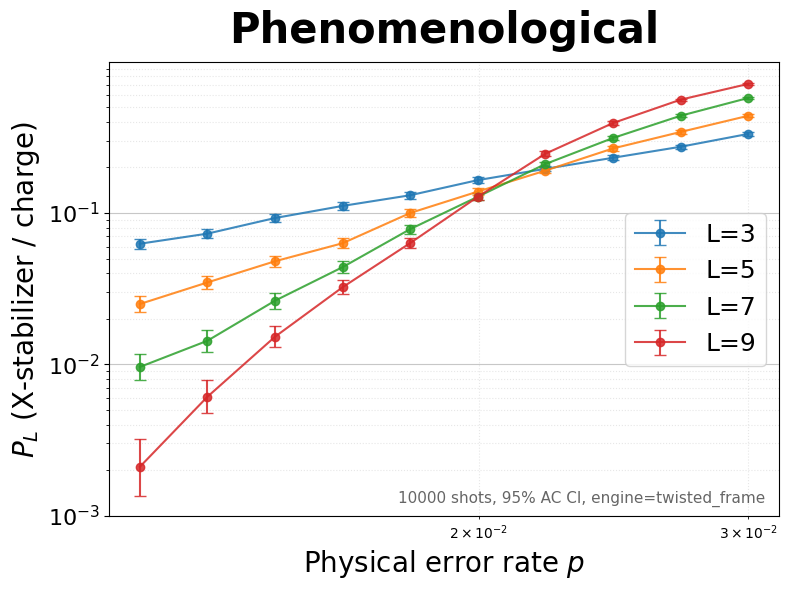

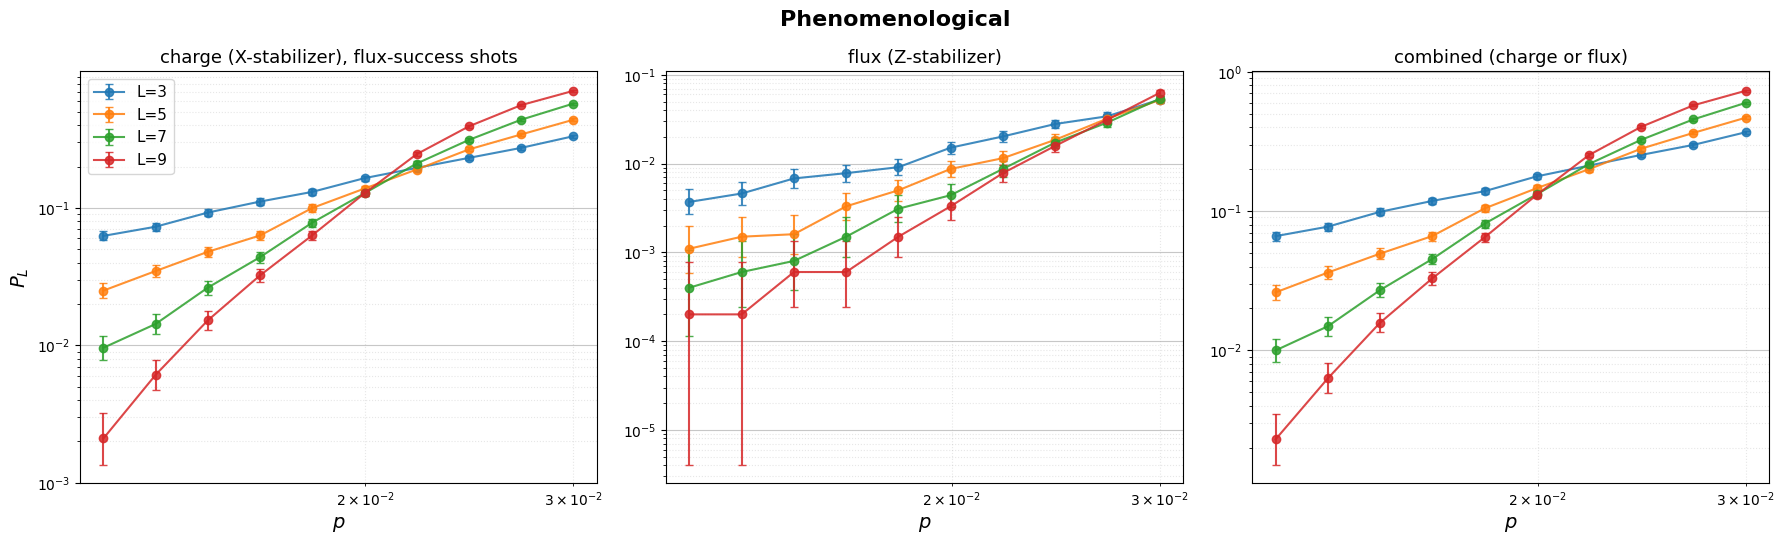

In [9]:
def calc_agresti_coull_interval(
    n_trials: int,
    n_failures: int,
    alpha: float = 0.05,
) -> Tuple[float, float, float]:
    if n_trials == 0:
        return 0.0, 0.0, 0.0

    z = norm.ppf(1 - alpha / 2) if SCIPY_AVAILABLE else 1.96
    n_tilde = n_trials + z ** 2
    p_tilde = (n_failures + z ** 2 / 2) / n_tilde
    se_tilde = math.sqrt(p_tilde * (1 - p_tilde) / n_tilde)
    return (
        p_tilde,
        max(0.0, p_tilde - z * se_tilde),
        min(1.0, p_tilde + z * se_tilde),
    )


def _reshape_bool_matrix(arr: np.ndarray, shots: int, width: int) -> np.ndarray:
    arr = np.asarray(arr, dtype=np.bool_)
    if width == 0:
        return np.zeros((shots, 0), dtype=np.bool_)
    if arr.ndim == 1:
        if shots == 1 and arr.size == width:
            return arr.reshape(1, width)
        if width == 1 and arr.size == shots:
            return arr.reshape(shots, 1)
    return arr.reshape(shots, width)


def _sample_dem(dem: "stim.DetectorErrorModel", shots: int) -> Tuple[np.ndarray, np.ndarray]:
    sampler = dem.compile_sampler()
    try:
        dets, obs = sampler.sample(shots, separate_observables=True)
    except TypeError:
        out = sampler.sample(shots)
        if isinstance(out, tuple) and len(out) >= 2:
            dets, obs = out[0], out[1]
        else:
            arr = np.asarray(out, dtype=np.bool_)
            nd = dem.num_detectors
            dets, obs = arr[:, :nd], arr[:, nd:]

    dets = _reshape_bool_matrix(np.asarray(dets, dtype=np.bool_), shots, dem.num_detectors)
    obs = _reshape_bool_matrix(np.asarray(obs, dtype=np.bool_), shots, dem.num_observables)
    return dets, obs


def _decode_observables(
    matcher: "pymatching.Matching",
    dets: np.ndarray,
    n_observables: int,
) -> np.ndarray:
    pred = matcher.decode_batch(dets)
    pred = np.asarray(pred, dtype=np.bool_)
    return _reshape_bool_matrix(pred, dets.shape[0], n_observables)


def _estimate_failure_rate(
    arts: DemXArtifacts,
    *,
    shots: int,
) -> float:
    matcher = pymatching.Matching.from_detector_error_model(arts.dem)
    dets, obs = _sample_dem(arts.dem, shots)
    pred = _decode_observables(matcher, dets, arts.n_observables)
    return float(np.mean(np.any(pred != obs, axis=1)))


def _resolve_noise_model_name(name: str) -> str:
    aliases = {
        "depolarizing": "depolarizing_surrogate_v2",
        "depolarizing_surrogate_v2": "depolarizing_surrogate_v2",
        "depolarizing_graphlike_dressed": "depolarizing_surrogate_v2",
        "depolarizing_effective_xcheck": "depolarizing_surrogate_v2",
        "phenomenological": "phenomenological",
        "circuit_level": "circuit_level",
    }
    if name not in aliases:
        raise ValueError(f"Unknown noise_model: {name}")
    return aliases[name]


def _resolve_rounds(model_name: str, L: int) -> int:
    """v6: depolarizing（符号容量型）は depolarizing_rounds を優先。それ以外は旧版通り rounds=None -> L。"""
    if model_name == "depolarizing_surrogate_v2" and CFG.get("depolarizing_rounds") is not None:
        return int(CFG["depolarizing_rounds"])
    return L if CFG["rounds"] is None else int(CFG["rounds"])


def run_one_point(
    *,
    L: int,
    p: float,
    shots: int,
    noise_model: str,
    depolarizing_overrides: Optional[Dict[str, object]] = None,
    phenomenological_overrides: Optional[Dict[str, object]] = None,
) -> Dict[str, float]:
    if stim is None or pymatching is None:
        raise RuntimeError("Stim and PyMatching are required.")

    if str(CFG.get("engine", "stim_surrogate")) == "twisted_frame":  # v6 既定エンジン
        if depolarizing_overrides or phenomenological_overrides:
            raise ValueError("overrides are only supported by engine='stim_surrogate'")
        return run_one_point_tf(L=L, p=p, shots=shots, noise_model=noise_model)

    model_name = _resolve_noise_model_name(str(noise_model))
    lat = TriangulatedTorus.build(L)
    stabs = build_d4_stabilizers(lat)
    rounds = _resolve_rounds(model_name, L)

    if model_name == "phenomenological":
        pheno = phenomenological_overrides or {}
        arts = build_phenomenological_x_circuit(
            stab=stabs,
            rounds=rounds,
            p=p,
            data_scale=pheno.get("data_scale"),
            meas_scale=pheno.get("meas_scale"),
            kickback_scale=pheno.get("kickback_scale"),
        )
    elif model_name == "depolarizing_surrogate_v2":
        overrides = depolarizing_overrides or {}
        arts = build_depolarizing_x_circuit(
            stab=stabs,
            rounds=rounds,
            p=p,
            data_scale=overrides.get("data_scale"),
            meas_scale=overrides.get("meas_scale"),
            dressing_scale=overrides.get("dressing_scale"),
            dressing_mode=overrides.get("dressing_mode"),
        )
    elif model_name == "circuit_level":
        arts = build_circuit_level_x_circuit(stab=stabs, rounds=rounds, p=p)
    else:
        raise AssertionError("unreachable")

    matcher = pymatching.Matching.from_detector_error_model(arts.dem)
    # v7: 元の回路から seed 付きで標本化（DEM は復号器の重みにだけ使う）
    seed = int(np.random.SeedSequence([int(CFG.get("seed", 0)), int(L), int(round(p * 1e12)), 7]).generate_state(1)[0])
    dets, obs = arts.circuit.compile_detector_sampler(seed=seed).sample(shots, separate_observables=True)
    pred = _decode_observables(matcher, dets, arts.n_observables)
    failures = np.any(pred != obs, axis=1)
    n_failures = int(np.sum(failures))

    alpha = 1.0 - float(CFG["confidence_level"])
    ac_p, ac_lower, ac_upper = calc_agresti_coull_interval(shots, n_failures, alpha)
    ler = n_failures / shots

    return {
        "engine": "stim_surrogate",
        "noise_model": str(noise_model),
        "L": float(L),
        "rounds": float(rounds),
        "p": float(p),
        "shots": float(shots),
        "n_failures": float(n_failures),
        "n_trials": float(shots),
        "logical_error_rate": float(ler),
        "ler_lower": float(ac_lower),
        "ler_upper": float(ac_upper),
        "ler_agresti_coull_center": float(ac_p),
        "n_detectors": float(arts.dem.num_detectors),
        "n_observables": float(arts.n_observables),
    }


def run_self_checks() -> Dict[str, object]:
    if stim is None or pymatching is None:
        raise RuntimeError("Stim and PyMatching are required for self-checks.")

    shots = int(CFG["self_check_shots"])
    L = int(CFG["L_values"][0])
    test_p = float(math.sqrt(float(CFG["p_min"]) * float(CFG["p_max"])))
    lat = TriangulatedTorus.build(L)
    stabs = build_d4_stabilizers(lat)
    rounds = _resolve_rounds("depolarizing_surrogate_v2", L)

    zero = run_one_point(
        L=L,
        p=0.0,
        shots=shots,
        noise_model="depolarizing_surrogate_v2",
    )
    if zero["n_failures"] != 0.0:
        raise AssertionError("p=0 should give LER=0 for the surrogate model.")

    arts = build_depolarizing_x_circuit(stab=stabs, rounds=rounds, p=test_p)
    matcher = pymatching.Matching.from_detector_error_model(arts.dem)
    dets, obs = _sample_dem(arts.dem, shots)
    pred = _decode_observables(matcher, dets, arts.n_observables)
    if pred.shape != obs.shape:
        raise AssertionError("Shape mismatch should be impossible in ver.2.")

    baseline = build_depolarizing_approx_baseline_circuit(
        stab=stabs,
        rounds=rounds,
        p=test_p,
    )
    off = build_depolarizing_x_circuit(
        stab=stabs,
        rounds=rounds,
        p=test_p,
        dressing_mode="off",
        dressing_scale=0.0,
    )
    if off.n_observables != baseline.n_observables:
        raise AssertionError("Off mode must preserve observable count.")
    if off.dem.num_detectors != baseline.dem.num_detectors:
        raise AssertionError("Off mode should preserve detector count.")
    baseline_ler = _estimate_failure_rate(baseline, shots=shots)
    off_ler = _estimate_failure_rate(off, shots=shots)
    if abs(off_ler - baseline_ler) > 0.20:
        raise AssertionError("Off mode drifted too far from the baseline proxy.")

    scales = [0.0, 0.15, 0.30]
    rate_profile = []
    for scale in scales:
        probe = build_depolarizing_x_circuit(
            stab=stabs,
            rounds=rounds,
            p=test_p,
            dressing_mode="pairwise_graphlike",
            dressing_scale=scale,
        )
        dets_s, obs_s = _sample_dem(probe.dem, shots)
        pred_s = _decode_observables(
            pymatching.Matching.from_detector_error_model(probe.dem),
            dets_s,
            probe.n_observables,
        )
        rate_profile.append(float(np.mean(np.any(pred_s != obs_s, axis=1))))

    if not (rate_profile[0] <= rate_profile[1] + 0.15 and rate_profile[1] <= rate_profile[2] + 0.15):
        raise AssertionError("Dressing sweep should vary continuously as the scale increases.")

    small_sweep = run_one_point(
        L=L,
        p=test_p,
        shots=shots,
        noise_model="depolarizing_surrogate_v2",
    )

    return {
        "p_zero_ler": zero["logical_error_rate"],
        "shape": {"pred": tuple(pred.shape), "obs": tuple(obs.shape)},
        "detectors": arts.dem.num_detectors,
        "observables": arts.n_observables,
        "baseline_detectors": baseline.dem.num_detectors,
        "off_detectors": off.dem.num_detectors,
        "baseline_ler": baseline_ler,
        "off_ler": off_ler,
        "dressing_rate_profile": dict(zip(scales, rate_profile)),
        "small_sweep_ler": small_sweep["logical_error_rate"],
    }


def run_experiments() -> pd.DataFrame:
    if stim is None or pymatching is None:
        raise RuntimeError("Stim and PyMatching are required.")

    L_values = [int(L) for L in CFG["L_values"]]
    shots = int(CFG["shots"])
    noise_model = _resolve_noise_model_name(str(CFG["noise_model"]))
    engine = str(CFG.get("engine", "stim_surrogate"))
    # v6: p_min/p_max/out_* が None なら、ノイズモデルごとの推奨値・自動ファイル名を使う
    rec = RECOMMENDED_P_RANGE.get(str(CFG["noise_model"]), (CFG["p_min"], CFG["p_max"]))
    p_min = float(rec[0] if CFG["p_min"] is None else CFG["p_min"])
    p_max = float(rec[1] if CFG["p_max"] is None else CFG["p_max"])
    p_n = int(CFG["p_n"])
    treat = str(CFG.get("dressing_treatment", "exact"))
    tag = f"d4_v7_X_memory_{CFG['noise_model']}_{engine}" + ("" if (engine != "twisted_frame" or treat == "exact") else f"_{treat}")
    out_csv = str(CFG["out_csv"] or (tag + ".csv"))
    out_png = str(CFG["out_png"] or (tag + ".png"))
    p_values = [p_min] if p_n == 1 else list(np.exp(np.linspace(np.log(p_min), np.log(p_max), p_n)))

    if CFG.get("print_geometry_summary", True):
        lat0 = TriangulatedTorus.build(L_values[0])
        st0 = build_d4_stabilizers(lat0)
        summary = summarize_geometry(st0)
        print("[D4 X-Stabilizer Geometry Summary]")
        print(
            f"  L={L_values[0]} vertices={int(summary['vertices'])} "
            f"edges={int(summary['edges'])} triangles={int(summary['triangles'])}"
        )
        print(
            f"  X checks={int(summary['x_checks'])} unique dressing pairs={int(summary['unique_dressing_pairs'])}"
        )
        print(
            f"  SrX CZ-pairs per vertex(avg)={summary['avg_red_pairs_per_vertex']:.2f} "
            f"max dressing incidence={int(summary['max_dressing_incidence'])}"
        )
        if noise_model == "depolarizing_surrogate_v2":
            print("  surrogate=effective graphlike depolarizing (not exact circuit-level depolarizing)")
            print(
                "  mode="
                f"{CFG['depolarizing_dressing_mode']} "
                f"dressing_scale={CFG['depolarizing_dressing_scale']:.3f} "
                f"data_scale={CFG['depolarizing_data_scale']:.3f} "
                f"meas_scale={CFG['depolarizing_meas_scale']:.3f}"
            )
        elif noise_model == "phenomenological":
            print("  surrogate=phenomenological with per-CZ-pair Z kickback")
            print(
                f"  kickback_scale={CFG['phenomenological_kickback_scale']:.3f} "
                f"data_scale={CFG['phenomenological_data_scale']:.3f} "
                f"meas_scale={CFG['phenomenological_meas_scale']:.3f}"
            )
        if engine == "twisted_frame":
            print("  [v7] engine=twisted_frame: dressed X checks are measured EXACTLY (non-commutativity included);")
            print(f"       dressing_treatment={treat}  (exact = D4 code; none / kappa_injection = control experiments)")
            print(f"       primary failure metric = {CFG['failure_metric']} (charge = X-stabilizer side, conditioned on flux success)")
            print(f"       charge-decoder prior: tf_decoder_kappa={decoder_kappa(str(CFG['noise_model']))}, "
                  f"cl_decoder_prior={CFG.get('cl_decoder_prior', 'calibrated')}")
            print(f"       logical_colors={CFG['logical_colors']} x_check_order={CFG['x_check_order']} "
                  f"jit_boundary_offset={CFG['jit_boundary_offset']} rounds={_resolve_rounds(noise_model, L_values[0])} (L={L_values[0]})")
        else:
            print("  [v7] engine=stim_surrogate: PREVIOUS-STUDY surrogate (bare MPP + r=kappa*c*p); non-commutativity NOT modeled.")
        print()

    if bool(CFG.get("save_manifest", True)):
        save_manifest(os.path.splitext(out_csv)[0] + "_manifest.json", extra=dict(p_values=[float(x) for x in p_values]))

    if bool(CFG.get("run_self_checks", False)) and engine == "twisted_frame":
        print("[Self-checks v7]")
        for key, val in run_self_checks_v6().items():
            print(f"  {key}: {val}")
        print()
    elif bool(CFG.get("run_self_checks", False)):
        print("[Self-checks]")
        checks = run_self_checks()
        print(f"  p=0 LER={checks['p_zero_ler']:.6f}")
        print(f"  pred/obs shape={checks['shape']['pred']} / {checks['shape']['obs']}")
        print(f"  off/baseline LER={checks['off_ler']:.6f} / {checks['baseline_ler']:.6f}")
        print(f"  dressing profile={checks['dressing_rate_profile']}")
        print(f"  small-shot LER={checks['small_sweep_ler']:.6f}")
        print()

    rows: List[Dict[str, float]] = []
    print(
        "Starting sweep "
        f"(noise={noise_model}, shots={shots}, CI={CFG['confidence_level'] * 100:.0f}% AC)..."
    )
    start = time.time()

    for L in L_values:
        for p in p_values:
            res = run_one_point(L=L, p=float(p), shots=shots, noise_model=noise_model)
            rows.append(res)
            pd.DataFrame(rows).to_csv(out_csv, index=False)  # 1 点ごとにチェックポイント保存
            extra = ""
            if engine == "twisted_frame":
                extra = (f" | charge={res['ler_charge']:.5f} flux={res['ler_flux']:.5f} "
                         f"combined={res['ler_combined']:.5f}")
            print(
                f"  [ok] L={L:2d} | p={p:.4e} | "
                f"LER={res['logical_error_rate']:.5f} "
                f"(95% CI: [{res['ler_lower']:.5f}, {res['ler_upper']:.5f}])" + extra
            )

    print(f"Sweep completed in {time.time() - start:.2f} seconds.\n")

    df = pd.DataFrame(rows)
    df.to_csv(out_csv, index=False)
    print(f"Saved CSV: {out_csv}")

    fig, ax = plt.subplots(figsize=(8, 6))
    palette = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:brown"]
    for idx, L in enumerate(L_values):
        sub = df[df["L"] == float(L)].sort_values("p")
        x = sub["p"].to_numpy()
        y = np.maximum(sub["logical_error_rate"].to_numpy(), 1e-10)
        y_lower = sub["ler_lower"].to_numpy()
        y_upper = sub["ler_upper"].to_numpy()
        yerr_low = np.maximum(0.0, y - y_lower)
        yerr_high = np.maximum(0.0, y_upper - y)
        ax.errorbar(
            x,
            y,
            yerr=[yerr_low, yerr_high],
            fmt="-o",
            capsize=4,
            label=f"L={L}",
            color=palette[idx % len(palette)],
            alpha=0.85,
        )

    display_names = {
        # v6: 測定誤りなし（符号容量型）のときはそれが分かるように表示
        "depolarizing": "Depolarizing (code capacity)" if float(CFG["depolarizing_meas_scale"]) == 0.0 else "Depolarizing",
        "phenomenological": "Phenomenological",
        "circuit_level": "Circuit-level",
    }
    model_display = display_names.get(str(CFG["noise_model"]), str(CFG["noise_model"]))

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel(r"Physical error rate $p$", fontsize=20)
    ylab = {"charge": r"$P_L$ (X-stabilizer / charge)", "combined": r"$P_L$ (charge or flux)",
            "flux": r"$P_L$ (flux)"}.get(str(CFG.get("failure_metric", "charge")), r"Logical error rate $P_L$")
    ax.set_ylabel(ylab if engine == "twisted_frame" else r"Logical error rate $P_L$", fontsize=20)
    ax.set_title(model_display, fontsize=30, fontweight="bold", pad=14)
    ax.tick_params(axis="both", which="major", labelsize=16)
    ax.grid(True, which="major", linestyle="-", alpha=0.7)
    ax.grid(True, which="minor", linestyle=":", alpha=0.3)
    ax.legend(fontsize=18)
    ax.text(
        0.98, 0.02, f"{shots} shots, 95% AC CI, engine={engine}" + (f", {treat}" if engine == "twisted_frame" and treat != "exact" else ""),
        transform=ax.transAxes, ha="right", va="bottom",
        fontsize=11, alpha=0.6,
    )
    fig.tight_layout()

    fig.savefig(out_png, dpi=200)
    print(f"Saved PNG: {out_png}")
    if bool(CFG.get("save_pdf", False)):
        pdf_path = os.path.splitext(out_png)[0] + ".pdf"
        fig.savefig(pdf_path)
        print(f"Saved PDF: {pdf_path}")

    if engine == "twisted_frame":
        plot_components(df, L_values, os.path.splitext(out_png)[0] + "_components.png", model_display)

    # 隣り合う L の曲線の交点（記述的な推定。有限サイズスケーリングではない）。v7: 指標ごとに出す
    try:
        metrics = list(METRIC_KEYS) if engine == "twisted_frame" else [None]
        allrows = []
        print("\n[Pairwise crossings of neighbouring L (descriptive; log-log interpolation, binomial bootstrap)]")
        for met in metrics:
            cross = estimate_crossings(df, metric=met)
            for row in cross:
                row["metric"] = met or "logical_error_rate"
                allrows.append(row)
                print("  [{}] L={}-{}: crossings={} ; bootstrap 68% / 95% interval (unique-crossing draws) = {} / {} ; "
                      "draws without/with multiple crossings: {} / {}".format(
                          row["metric"], row["L_a"], row["L_b"], ["%.4e" % c for c in row["crossings"]],
                          row["ci68"], row["ci95"], row["no_crossing_draws"], row["multiple_crossing_draws"]))
        pd.DataFrame(allrows).to_csv(os.path.splitext(out_csv)[0] + "_crossings.csv", index=False)
    except Exception as exc:  # noqa: BLE001
        print(f"[crossing estimate skipped: {exc}]")

    return df




def estimate_crossings(df: pd.DataFrame, n_boot: int = 400, metric: Optional[str] = None) -> List[Dict[str, object]]:
    """隣り合う L の LER 曲線の交点を log-log 線形補間で求め、二項分布（Jeffreys 事後）で揺らして区間を付ける。
    記述的な推定であり、有限サイズスケーリングによる閾値推定ではない。
    metric: None なら主指標（logical_error_rate / n_failures / n_trials）、"charge"/"combined"/"flux" ならその指標。"""
    col_r, col_k, col_n = ("logical_error_rate", "n_failures", "n_trials") if metric is None else \
        (f"ler_{metric}", f"n_fail_{metric}", f"n_trials_{metric}")
    if col_n not in df.columns:
        col_n = "shots"
    rng = np.random.default_rng(int(CFG.get("seed", 0)) + 917)
    rows = []
    sizes = sorted(df["L"].unique())
    for a, b in zip(sizes[:-1], sizes[1:]):
        u = df[df["L"] == a].sort_values("p")
        v = df[df["L"] == b].sort_values("p")
        if not np.allclose(u["p"].to_numpy(), v["p"].to_numpy()):
            raise ValueError("p grids differ between L values")
        p = u["p"].to_numpy()

        def roots(ya, yb):
            y = np.log(np.maximum(ya, 1e-12)) - np.log(np.maximum(yb, 1e-12))
            out = []
            for i in range(len(p) - 1):
                if y[i] * y[i + 1] < 0:
                    lp = np.log(p[i]) - y[i] * (np.log(p[i + 1]) - np.log(p[i])) / (y[i + 1] - y[i])
                    out.append(float(np.exp(lp)))
            return out

        est = roots(u[col_r].to_numpy(), v[col_r].to_numpy())
        draws, none_, multi = [], 0, 0
        for _ in range(n_boot):
            ka, na = u[col_k].to_numpy(), u[col_n].to_numpy()
            kb, nb = v[col_k].to_numpy(), v[col_n].to_numpy()
            r = roots(rng.beta(ka + 0.5, na - ka + 0.5), rng.beta(kb + 0.5, nb - kb + 0.5))
            if len(r) == 1:
                draws.append(r[0])
            elif not r:
                none_ += 1
            else:
                multi += 1
        ci68 = ["%.4e" % q for q in np.quantile(draws, [0.16, 0.84])] if draws else None
        ci95 = ["%.4e" % q for q in np.quantile(draws, [0.025, 0.975])] if draws else None
        rows.append(dict(L_a=int(a), L_b=int(b), crossings=est, ci68=ci68, ci95=ci95,
                         unique_draws=len(draws), no_crossing_draws=none_, multiple_crossing_draws=multi))
    return rows


def run_self_checks_v6() -> Dict[str, object]:
    """v6 (twisted_frame) の自己診断。"""
    L = int(CFG["L_values"][0])
    stab = build_d4_stabilizers(TriangulatedTorus.build(L))
    op_nc, flat_nc = count_noncommuting_x_check_pairs(stab)
    if flat_nc != 0:
        raise AssertionError("dressed X checks must commute on the flat subspace (geometry bug)")
    shots = int(CFG["self_check_shots"])
    samp = sample_tf_memory(str(CFG["noise_model"]), L, 0.0, shots, int(CFG.get("seed", 0)))
    if samp["dets"].any():
        raise AssertionError("p=0 must give no detection events")
    zero = run_one_point_tf(L=L, p=0.0, shots=shots, noise_model=str(CFG["noise_model"]))
    if zero["n_fail_combined"] != 0:
        raise AssertionError("p=0 must give no logical failures")
    return {"L": L, "operator-level noncommuting X-check pairs": op_nc,
            "noncommuting pairs on the flat subspace (must be 0)": flat_nc,
            "p=0 detection events": int(samp["dets"].sum()), "p=0 failures": int(zero["n_fail_combined"])}


def plot_components(df: pd.DataFrame, L_values, out_png: str, title: str) -> None:
    """v7: 3 つの指標（charge / flux / combined）を並べた図。"""
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharex=True)
    palette = ["tab:blue", "tab:orange", "tab:green", "tab:red", "tab:brown"]
    names = {"charge": "charge (X-stabilizer), flux-success shots", "flux": "flux (Z-stabilizer)",
             "combined": "combined (charge or flux)"}
    for ax, met in zip(axes, ("charge", "flux", "combined")):
        for idx, L in enumerate(L_values):
            sub = df[df["L"] == float(L)].sort_values("p")
            y = np.maximum(sub[f"ler_{met}"].to_numpy(), 1e-10)
            ax.errorbar(sub["p"], y, yerr=[np.maximum(0, y - sub[f"ler_{met}_lower"]), np.maximum(0, sub[f"ler_{met}_upper"] - y)],
                        fmt="-o", capsize=3, label=f"L={L}", color=palette[idx % len(palette)], alpha=0.85)
        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_title(names[met], fontsize=13)
        ax.set_xlabel(r"$p$", fontsize=14)
        ax.grid(True, which="major", alpha=0.7)
        ax.grid(True, which="minor", linestyle=":", alpha=0.3)
    axes[0].set_ylabel(r"$P_L$", fontsize=14)
    axes[0].legend(fontsize=11)
    fig.suptitle(title, fontsize=16, fontweight="bold")
    fig.tight_layout()
    fig.savefig(out_png, dpi=160)
    if bool(CFG.get("save_pdf", False)):
        fig.savefig(os.path.splitext(out_png)[0] + ".pdf")
    print(f"Saved components figure: {out_png}")


def save_manifest(path: str, extra: Optional[Dict[str, object]] = None) -> None:
    """v7: 実行条件の記録（CFG 全体、依存パッケージの版、日時、環境）。"""
    import json, platform, datetime, importlib.metadata as _md
    vers = {}
    for pkg in ("numpy", "scipy", "stim", "pymatching", "numba", "pandas", "matplotlib", "jax"):
        try:
            vers[pkg] = _md.version(pkg)
        except Exception:  # noqa: BLE001
            vers[pkg] = None
    rec = dict(code_version="v7", datetime=datetime.datetime.now().isoformat(), python=platform.python_version(),
               platform=platform.platform(), versions=vers, CFG={k: (v if isinstance(v, (int, float, str, bool, type(None), list, dict)) else str(v))
                                                                  for k, v in CFG.items()})
    if "VCFG" in globals():
        rec["VCFG"] = {k: (v if isinstance(v, (int, float, str, bool, type(None), list, dict)) else str(v)) for k, v in VCFG.items()}
    if extra:
        rec.update(extra)
    with open(path, "w") as fh:
        json.dump(rec, fh, indent=2, ensure_ascii=False, default=str)
    print(f"Saved manifest: {path}")


if __name__ == "__main__":
    results = run_experiments()

# v7 の解釈と実行手順

**GPU 不要（CPU ランタイム）。** 所要時間の目安（手元の CPU）: 1 ショットあたり L=7 で 1–4 ms、L=9 で 2–6 ms 程度です（ノイズモデルにより異なる）。

- 出力: `d4_v7_X_memory_<model>_<engine>.csv / .png / .pdf`、3 指標を並べた `..._components.png`、指標ごとの交点 `..._crossings.csv`、実行条件 `..._manifest.json`。CSV は 1 点ごとに上書き保存されます。終了後に Google Drive へ保存してください。
- CSV の主な列:
  - `ler_charge`（= `n_fail_charge / n_trials_charge`）: X スタビライザ側の論理エラー率。flux 側が成功したショットに条件付けた値（分母 = shots − n_fail_flux）。**X スタビライザの閾値はこの指標で求めます。**
  - `ler_flux`: 終了時に非自明な X ループが残った割合（Z スタビライザ側）。`ler_combined`: どちらかの失敗（v6 の `logical_error_rate`）。
  - `logical_error_rate`, `n_failures`, `n_trials`: `failure_metric` で選んだ主指標。
  - `mean_infidelity_flux_ok`（flux 成功ショットの平均非忠実度）、`n_fractional_F`（忠実度が 0 でも 1 でもなかったショット数）、`frac_random_outcomes`（dressed X チェック測定のうち結果が確率 1/2 になった割合）、`jit_flips_per_shot`。
- 交点の推定は、隣り合う L の曲線を log–log で線形補間した記述的なものです（有限サイズスケーリングではありません）。L=3 は復号器の設定の影響を強く受けるため、閾値の評価には大きい L の組（5–7, 7–9）を重視してください。本番では `L_values=[3, 5, 7, 9]` を推奨します。
- 対照実験: `dressing_treatment="none"`（dressing なし）と `"kappa_injection"`（dressing なし + 旧研究の $r=\kappa c p$ 注入）を同じ p 範囲で実行すると、非可換性（dressing）の効果と、旧研究の近似がそれをどこまで表せるかを比較できます。

メモ：[3,5,7,9], 10000 shotsで12分